# 08 — Does radiation *increase* anything about SPP1-TAMs, spatially?

Notebooks 02/03 asked **where** SPP1-TAMs sit; 06 asked **how much** treatment changes their
burden. Neither asked the question this notebook exists for:

> **After radiation, does the SPP1-TAM program become more spatially organised, and more tightly
> coupled to the damage / lipid / oxidative niche?**

06 already showed the *abundance* answer is unhelpful for a "RT increases SPP1-TAMs" claim —
`mean_sig` moved +0.18 log2 in one CAR-T background and −0.19 in the other, and single-cell
prevalence (07) *falls* with every treatment. So abundance is not where the RT signal is. The
proposal's own logic says it should be in **spatial organisation**: RT makes damage-rich,
lipid-rich pockets, and the SPP1-TAM program should concentrate *into* them. That is a
Moran's-I-shaped question, not a fraction-shaped one.

### The design constraint, stated up front
There is **no RT-alone arm**. Every irradiated tissue also received Cy + CAR-T. So every contrast
here reads as *"adding RT on top of Cy + CAR-T"*, never *"RT vs untreated"*. `NoTx` is also
effectively absent from spatial macrophage analysis (7 of 8 NoTx tissues have <50 macrophages),
so it cannot serve as the baseline. The baseline is the **CAR-T-matched non-RT arm**:

| CAR-T background | irradiated | non-irradiated baseline |
|---|---|---|
| PSCA (specific)      | `RTCyPSCA_1` (n=4)  | `CyPSCA_1` (n=4) |
| TAG72 (non-specific) | `RTCyT72_1`  (n=3)  | `CyT72_1`  (n=2) |

Two independent CAR-T backgrounds → **the evidence is sign-consistency across both**, not a
p-value. `Tu1` is the irradiated tumour and `Tu2` the abscopal one in the same mouse, so
`Tu1 vs Tu2` inside an RT arm is a within-animal RT contrast as well.

### Three readouts, each with its own control

| § | Readout | What it would mean | Control |
|---|---|---|---|
| A | **Univariate Moran's I** of `SPP1_TAM_sig` across macrophages | the program is spatially clustered into niches rather than scattered | the same Moran's I on **expression-matched random gene signatures** in the same cells — if that rises too, the tissue just got more structured |
| B | **Bivariate (cross-set) Moran's I**: mac signature × pathway score of the **non-myeloid** cells around it | the program is *coupled* to the damage/lipid niche | contrast-tier pathways (IFN-γ, p53, inflammatory) must not move with the metabolic tier |
| C | the same coupling **in distance bands** (0-25, 25-50, 50-100, 100-150 µm) | the spatial *scale* of the coupling — the cross-variogram argument in Aim 1 | the curve must decay; a flat curve means a whole-tissue effect, not a niche |
| D | **Macrophage-intrinsic** metabolic pathway scores | the macrophages themselves shift to lipid/oxidative metabolism after RT | the same score in the non-myeloid compartment of the same tissue (`mac − stroma`), which cancels tissue-level depth/normalisation shifts |

§B/§C are the mouse counterpart of the human "8 Gy vs sham" result already in the proposal
(increased OXPHOS/fatty-acid metabolism, reduced IFN-γ around SPP1-TAM regions), and they are
literally the statistic Aim 1 proposes to develop. If they move in the mouse too, the preliminary
data spans both species.

**Prereqs:** `01c` §5 (writes `sc_spp1_tam_signature.csv`). 02/03 are *not* required.
Helpers are defined inline — the kernel runs on the HPC node and cannot see local `.py` files.

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch

import scanpy as sc
import spatialdata as spd

from sklearn.neighbors import NearestNeighbors
from statsmodels.stats.multitest import multipletests

try:
    from spatialdata.transformations import get_transformation
except Exception:
    get_transformation = None

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80); pd.set_option("display.width", 240)

/Users/janzules/miniforge3/envs/spatial_cpu_py311/lib/python3.11/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


/Users/janzules/miniforge3/envs/spatial_cpu_py311/lib/python3.11/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


## 1. Config

In [2]:
# Resolve HPC vs local copy. The local zarr is the same object under a different
# directory name (2,088,557 cells x 19,059 genes, c2l_consolidated, 32 images).
_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T")
_LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ_DIR  = _HPC if _HPC.exists() else _LOC
ZARR_FILE = (PROJ_DIR / "data/zarr/fullDataset/processing_Zarr/1_C2l_annotated_CC"
             if PROJ_DIR is _HPC else
             PROJ_DIR / "data/zarrFiles/1_C2l_annotations_400")
PATHWAY_DIR = PROJ_DIR / "data/references/pathways"
OUT_DIR     = PROJ_DIR / "results/spp1_analysis"
FIG_DIR     = OUT_DIR / "figures"
SIG_CSV     = OUT_DIR / "sc_spp1_tam_signature.csv"        # written by 01c §5
OUT_DIR.mkdir(parents=True, exist_ok=True); FIG_DIR.mkdir(parents=True, exist_ok=True)
assert SIG_CSV.exists(), f"run 01c §5 first — missing {SIG_CSV}"

GMT_FILES = {
    "hallmark": PATHWAY_DIR / "mh.all.v2026.1.Mm.symbols.gmt",
    "reactome": PATHWAY_DIR / "m2.cp.reactome.v2026.1.Mm.symbols.gmt",
    "go_bp":    PATHWAY_DIR / "m5.go.bp.v2026.1.Mm.symbols.gmt",
    "curated":  PATHWAY_DIR / "m2.cp.v2026.1.Mm.symbols.gmt",
}

TISSUE_COL, CELL_TYPE_COL = "tissue", "c2l_consolidated"
MAC_LABELS     = ["M1_like_Mac", "M2_like_Mac", "Intermediate_Mac"]
# same exclusions as 02/03: macs + their monocyte precursors + neutrophils cannot define the
# niche they are being tested against, or the coupling is circular by construction.
MYELOID_LABELS = MAC_LABELS + ["Classical_Mono", "Nonclassical_Mono", "Monocyte", "Macrophage",
                               "N1_like_Neu", "N2_like_Neu", "Neutrophil"]
EXCLUDE_FROM_NICHE = set(MYELOID_LABELS) | {"Unknown", "Erythrocyte"}

# The design, as attributes. Spatial spells the non-specific arm CyT72/RTCyT72 (single-cell
# spells it CyTAG72) — these keys must match the spatial `tissue` strings.
COND_META = {
    "NoTx":     {"RT": False, "cart": "none",        "cy": False},
    "CyT72":    {"RT": False, "cart": "nonspecific", "cy": True},
    "CyPSCA":   {"RT": False, "cart": "PSCA",        "cy": True},
    "RTCyT72":  {"RT": True,  "cart": "nonspecific", "cy": True},
    "RTCyPSCA": {"RT": True,  "cart": "PSCA",        "cy": True},
}
CONDITION_ORDER = ["NoTx", "CyT72", "CyPSCA", "RTCyT72", "RTCyPSCA"]
# (cart background, irradiated arm, matched non-irradiated arm) — the RT contrast, run twice
CART_PAIRS = [("PSCA", "RTCyPSCA", "CyPSCA"), ("nonspecific", "RTCyT72", "CyT72")]

MICRONS_PER_PIXEL, APPLY_HIRES_SCALE = 0.34, True

K_MORAN            = 15      # kNN weights for the univariate Moran's I (density-adaptive)
MORAN_MAX_DIST_UM  = 100     # sensitivity run: drop kNN edges longer than this
N_PERM             = 999     # permutation null
NICHE_RADIUS_UM    = 50      # §B headline coupling radius (matches 02)
BAND_EDGES_UM      = [0, 25, 50, 100, 150]     # §C distance bands
MAX_MACS_FOR_BANDS = 1500    # subsample per tissue in §C so the 150 µm graph stays small
MIN_MACS_FOR_MORAN = 150     # below this a per-tissue Moran's I is not interpretable
MIN_NB             = 3       # min niche cells in a band for a mac to contribute
MIN_CELLS          = 100
MIN_MATCHED_GENES  = 5
MIN_TISSUES_PER_SIDE = 2     # a contrast needs >= this many tissues on each side
N_RANDOM_SIGS      = 3       # expression-matched random signatures (the §A control)
SEED               = 0

TISSUE_SUBSET = None         # e.g. ["RTCyPSCA_1_3","CyPSCA_1_3"] to smoke-test the whole notebook

RT_C, NORT_C, ABS_C = "#d62728", "#4d4d4d", "#1f77b4"
print("config ready ->", OUT_DIR)

config ready -> /Users/janzules/Roselab/Spatial/CAR_T/results/spp1_analysis


## 2. Engine — spatial weights, Moran's I, cross-set bivariate Moran's I

All inline. Three statistics:

- `morans_i` — the standard row-standardised-kNN Moran's I with a permutation null.
- `cross_moran_bands` — bivariate Moran's I with a **cross-set** weight matrix: rows are
  macrophages, columns are the non-myeloid cells in a distance band around them. `I = z_x' W z_y / n`
  answers *"is a macrophage's SPP1-TAM level aligned with the pathway activity of the cells at
  distance d from it?"*. Its null permutes the **signature values among the macrophages that are
  actually there**, which holds the niche field and the macrophage positions fixed — so a
  significant result means the *program* is non-randomly placed, not that macrophages are.
- `r_lag` is reported next to `I_cross`: the plain Pearson r between the signature and the banded
  neighbour mean. `I_cross` inherits the lag's variance, which depends on how many neighbours fall
  in the band, so **`r_lag` is the number to compare across tissues** and `I_cross` is the Moran
  statistic proper. They carry the same sign and rank.

In [3]:
def _z(v):
    """z-standardize; None if degenerate."""
    v = np.asarray(v, float)
    s = np.nanstd(v)
    if not np.isfinite(s) or s == 0:
        return None
    return (v - np.nanmean(v)) / s


def get_scale(sdata, t):
    k = f"{t}_cell_boundaries"
    if get_transformation is None or k not in sdata.shapes:
        return 1.0
    try:
        return float(get_transformation(sdata.shapes[k], get_all=True)["downscale_to_hires"].scale[0])
    except Exception:
        return 1.0


def coords_um_for(adata, sdata, t):
    mask = adata.obs[TISSUE_COL].astype(str).eq(str(t)).values
    c = np.asarray(adata.obsm["spatial"][mask], float)
    s = get_scale(sdata, t) if APPLY_HIRES_SCALE else 1.0
    return mask, c * s * MICRONS_PER_PIXEL


def knn_W(xy, k=K_MORAN, max_dist=None):
    """Row-standardized kNN weights, self excluded. Returns (W, kept_idx, median_kNN_dist_um).

    kNN (not fixed radius) on purpose: macrophage density varies ~100x across these tissues, and
    a fixed-radius W would make Moran's I a density readout instead of an organization readout.
    """
    n = len(xy)
    k_eff = min(k, n - 1)
    if k_eff < 3:
        return None, None, np.nan
    nn = NearestNeighbors(n_neighbors=k_eff + 1).fit(xy)
    d, idx = nn.kneighbors(xy)
    d, idx = d[:, 1:], idx[:, 1:]                     # drop self
    med_d = float(np.median(d[:, -1]))                # median distance to the k-th neighbour
    keep = np.ones(d.shape, bool) if max_dist is None else (d <= max_dist)
    rows = np.repeat(np.arange(n), k_eff)[keep.ravel()]
    cols = idx.ravel()[keep.ravel()]
    if rows.size == 0:
        return None, None, med_d
    W = sp.csr_matrix((np.ones(rows.size), (rows, cols)), shape=(n, n))
    kept = np.where(np.asarray(W.sum(1)).ravel() > 0)[0]
    for _ in range(5):                                # dropping columns can orphan a row; iterate
        Wk = W[kept][:, kept]
        deg = np.asarray(Wk.sum(1)).ravel()
        if deg.size == 0 or (deg > 0).all():
            break
        kept = kept[deg > 0]
    if len(kept) < MIN_MACS_FOR_MORAN:
        return None, None, med_d
    deg = np.asarray(Wk.sum(1)).ravel()
    return (sp.diags(1.0 / deg) @ Wk).tocsr(), kept, med_d


def morans_i(W, x, n_perm=N_PERM, rng=None):
    """Moran's I with row-standardized W (so S0 = n and I = z'Wz / n) + permutation null."""
    z = _z(x)
    if z is None or W is None:
        return {"I": np.nan, "p_perm": np.nan, "z_perm": np.nan}
    n = len(z)
    I = float(z @ (W @ z)) / n
    rng = np.random.default_rng(SEED) if rng is None else rng
    null = np.empty(n_perm)
    for b in range(n_perm):
        zp = rng.permutation(z)
        null[b] = float(zp @ (W @ zp)) / n
    mu, sd = float(null.mean()), float(null.std())
    p = (1 + int((np.abs(null - mu) >= abs(I - mu)).sum())) / (n_perm + 1)
    return {"I": I, "p_perm": p, "z_perm": (I - mu) / (sd + 1e-12)}


def cross_moran_bands(mac_xy, niche_xy, x_mac, y_niche, edges, n_perm=N_PERM, rng=None,
                      min_units=MIN_MACS_FOR_MORAN):
    """Bivariate Moran's I between a mac-level variable x and a niche-cell-level variable y,
    in concentric distance bands. One row per band.

    Null: permute x among the macrophages present (y field and all positions held fixed).
    """
    rng = np.random.default_rng(SEED) if rng is None else rng
    zx_all, zy = _z(x_mac), _z(y_niche)
    out = []
    if zx_all is None or zy is None:
        return out
    nn = NearestNeighbors(radius=float(max(edges))).fit(niche_xy)
    lag_prev = np.zeros(len(mac_xy)); cnt_prev = np.zeros(len(mac_xy))
    for lo, hi in zip(edges[:-1], edges[1:]):
        G = nn.radius_neighbors_graph(mac_xy, radius=float(hi), mode="connectivity")
        lag_cum = np.asarray(G @ zy).ravel()
        cnt_cum = np.asarray(G.sum(1)).ravel()
        del G
        lag, cnt = lag_cum - lag_prev, cnt_cum - cnt_prev     # annulus = ball(hi) - ball(lo)
        lag_prev, cnt_prev = lag_cum, cnt_cum
        row = {"band": f"{lo}-{hi}", "band_lo": lo, "band_hi": hi,
               "I_cross": np.nan, "r_lag": np.nan, "p_perm": np.nan,
               "n_mac": 0, "mean_nb": np.nan}
        ok = cnt >= MIN_NB
        if ok.sum() >= min_units:
            lag_bar = lag[ok] / cnt[ok]                       # row-standardized spatial lag of y
            zx = _z(zx_all[ok])
            if zx is not None and np.std(lag_bar) > 0:
                I = float(zx @ lag_bar) / len(zx)
                null = np.empty(n_perm)
                for b in range(n_perm):
                    null[b] = float(rng.permutation(zx) @ lag_bar) / len(zx)
                row.update(I_cross=I, r_lag=float(np.corrcoef(zx, lag_bar)[0, 1]),
                           p_perm=(1 + int((np.abs(null) >= abs(I)).sum())) / (n_perm + 1),
                           n_mac=int(ok.sum()), mean_nb=float(cnt[ok].mean()))
        out.append(row)
    return out


def parse_tissue(t):
    """SPATIAL naming: <cond>_<loc>_<rep>. loc 1 = irradiated, loc 2 = abscopal in RT arms."""
    m = re.match(r"^(.*)_(\d+)_(\d+)$", str(t))
    return (m.group(1), int(m.group(2)), int(m.group(3))) if m else (None, None, None)


def rt_status_of(cond, loc):
    if not COND_META.get(cond, {}).get("RT", str(cond).startswith("RT")):
        return "no_RT"
    return "irradiated" if loc == 1 else "abscopal"


def read_gmt(p):
    out = {}
    for line in open(p):
        x = line.rstrip("\n").split("\t")
        if len(x) >= 3:
            out[x[0]] = x[2:]
    return out


print("engine ready")

engine ready


## 3. The RT-contrast machinery

Every contrast the design supports, for any per-tissue metric. Run once per CAR-T background so
that **sign agreement between the two backgrounds is the evidence** — at n=2-4 tissues a side, a
p-value cannot carry the claim and is deliberately not computed here.

In [4]:
CONTRAST_SPECS = [
    # (label, RT-side selector, baseline selector) — built per CAR-T background
    ("RT-direct vs no-RT   [Tu1, loc-matched]",  ("rt", 1),  ("nort", 1)),
    ("RT-abscopal vs no-RT [Tu2, loc-matched]",  ("rt", 2),  ("nort", 2)),
    ("RT-direct vs no-RT   [pooled locs]",       ("rt", None), ("nort", None)),
    ("RT-direct vs RT-abscopal [within arm]",    ("rt", 1),  ("rt", 2)),
]


def _sel(d, side, arm_rt, arm_nort, loc):
    arm = arm_rt if side == "rt" else arm_nort
    m = d["cond"].eq(arm)
    if loc is not None:
        m &= d["tumor_loc"].eq(loc)
    return m


def rt_contrasts(df, value_col, group_cols=()):
    """Per-tissue metric -> tidy RT contrasts. df needs tissue/cond/tumor_loc + group_cols."""
    keys = list(group_cols)
    blocks = list(df.groupby(keys, observed=True)) if keys else [((), df)]
    rows = []
    for gkey, d in blocks:
        gkey = gkey if isinstance(gkey, tuple) else (gkey,)
        base = dict(zip(keys, gkey))
        for cart, arm_rt, arm_nort in CART_PAIRS:
            for label, (sa, la), (sb, lb) in CONTRAST_SPECS:
                a = d.loc[_sel(d, sa, arm_rt, arm_nort, la), value_col].dropna().values
                b = d.loc[_sel(d, sb, arm_rt, arm_nort, lb), value_col].dropna().values
                if len(a) < MIN_TISSUES_PER_SIDE or len(b) < MIN_TISSUES_PER_SIDE:
                    continue
                rows.append({**base, "cart": cart, "contrast": label,
                             "n_a": len(a), "n_b": len(b),
                             "mean_a": float(a.mean()), "mean_b": float(b.mean()),
                             "delta": float(a.mean() - b.mean()),
                             "frac_a_above_b_max": float((a > b.max()).mean())})
    return pd.DataFrame(rows)


def consistency(con, value="delta", label_cols=()):
    """Collapse the two CAR-T backgrounds: same sign in both = the claim; opposite = no claim."""
    keys = list(label_cols) + ["contrast"]
    out = []
    for gkey, d in con.groupby(keys, observed=True):
        gkey = gkey if isinstance(gkey, tuple) else (gkey,)
        dd = d.set_index("cart")[value]
        both = dd.reindex([c[0] for c in CART_PAIRS])
        n_ok = int(both.notna().sum())
        agree = bool(n_ok == 2 and np.sign(both.iloc[0]) == np.sign(both.iloc[1]))
        out.append({**dict(zip(keys, gkey)),
                    "delta_PSCA": both.get("PSCA", np.nan),
                    "delta_nonspecific": both.get("nonspecific", np.nan),
                    "mean_delta": float(both.mean()) if n_ok else np.nan,
                    "n_backgrounds": n_ok, "sign_agree": agree})
    return pd.DataFrame(out)


print("contrast machinery ready:", [c[0] for c in CONTRAST_SPECS])

contrast machinery ready: ['RT-direct vs no-RT   [Tu1, loc-matched]', 'RT-abscopal vs no-RT [Tu2, loc-matched]', 'RT-direct vs no-RT   [pooled locs]', 'RT-direct vs RT-abscopal [within arm]']


## 4. Load, score the signature, score the pathway panel

The panel unions 02/03's niche panel with the **exact metabolic sets from Figure 3** (the
single-cell panel in 01c §4), so a mouse spatial result can be read directly against the
single-cell figure already in the proposal, and against the human 8 Gy-vs-sham panel.

In [5]:
sdata = spd.read_zarr(ZARR_FILE)
adata = sdata.tables["segmentation_counts"]

sig_genes = pd.read_csv(SIG_CSV)["gene"].tolist()
present = [g for g in sig_genes if g in adata.var_names]
print(f"signature: {len(present)}/{len(sig_genes)} genes present in spatial")
assert len(present) >= 8, "too few signature genes present"
sc.tl.score_genes(adata, gene_list=present, score_name="SPP1_TAM_sig", use_raw=False,
                  random_state=SEED)

ct = adata.obs[CELL_TYPE_COL].astype(str)
adata.obs["is_mac"]     = ct.isin(MAC_LABELS).values
adata.obs["niche_cell"] = ~ct.isin(EXCLUDE_FROM_NICHE).values
print(f"macrophages: {int(adata.obs['is_mac'].sum()):,} | "
      f"niche-defining cells: {int(adata.obs['niche_cell'].sum()):,}")

signature: 48/50 genes present in spatial


macrophages: 81,565 | niche-defining cells: 550,277


In [6]:
# ---- the pathway panel: 02/03's niche panel + Figure 3's metabolic sets ----
PANEL = {
    # --- the mechanism the proposal argues RT creates ---
    "oxLDL_Response":        ("GOBP_CELLULAR_RESPONSE_TO_OXIDISED_LOW_DENSITY_LIPOPROTEIN_PARTICLE_STIMULUS", "metabolic", "Oxidized LDL response"),
    "Scavenger_Uptake":      ("REACTOME_BINDING_AND_UPTAKE_OF_LIGANDS_BY_SCAVENGER_RECEPTORS", "metabolic", "Scavenger-mediated lipid uptake"),
    "Lysosomal_Transport":   ("GOBP_LYSOSOMAL_TRANSPORT",            "metabolic", "Lysosomal transport"),
    "Lipid_Droplet":         ("GOBP_LIPID_DROPLET_ORGANIZATION",     "metabolic", "Lipid droplet organization"),
    "Cholesterol_Homeo":     ("HALLMARK_CHOLESTEROL_HOMEOSTASIS",    "metabolic", "Cholesterol handling"),
    "Cholesterol_Efflux":    ("GOBP_CHOLESTEROL_EFFLUX",             "metabolic", "Cholesterol efflux"),
    "FattyAcid_Metab":       ("HALLMARK_FATTY_ACID_METABOLISM",      "metabolic", "Fatty acid metabolism"),
    "Lipid_Oxidation":       ("GOBP_LIPID_OXIDATION",                "metabolic", "Lipid oxidation"),
    "FA_Beta_Oxidation":     ("GOBP_FATTY_ACID_BETA_OXIDATION",      "metabolic", "Fatty acid β-oxidation"),
    "OxPhos":                ("HALLMARK_OXIDATIVE_PHOSPHORYLATION",  "metabolic", "Oxidative phosphorylation"),
    # --- the RT-generated environment ---
    "Hypoxia":               ("HALLMARK_HYPOXIA",                    "damage",    "Hypoxia"),
    "Glycolysis":            ("HALLMARK_GLYCOLYSIS",                 "damage",    "Glycolysis"),
    "Apoptosis":             ("HALLMARK_APOPTOSIS",                  "damage",    "Apoptosis"),
    "P53_DNA_damage":        ("HALLMARK_P53_PATHWAY",                "damage",    "p53 / DNA damage"),
    "ECM":                   ("REACTOME_EXTRACELLULAR_MATRIX_ORGANIZATION", "damage", "ECM remodeling"),
    "Angiogenesis":          ("HALLMARK_ANGIOGENESIS",               "damage",    "Angiogenesis"),
    # --- contrast tier: these EARN the claim. If they move like the metabolic tier, nothing here
    #     is niche-specific and the whole result is a tissue-architecture artifact. ---
    "IFN_gamma":             ("HALLMARK_INTERFERON_GAMMA_RESPONSE",  "contrast",  "IFN-γ response"),
    "TNFa_NFkB":             ("HALLMARK_TNFA_SIGNALING_VIA_NFKB",    "contrast",  "TNF-α / NF-κB"),
    "Inflammatory":          ("HALLMARK_INFLAMMATORY_RESPONSE",      "contrast",  "Inflammatory response"),
}
TIER_OF  = {k: v[1] for k, v in PANEL.items()}
LABEL_OF = {k: v[2] for k, v in PANEL.items()}
TIER_ORDER = ["metabolic", "damage", "contrast"]

gene_sets = {}
for _, p in GMT_FILES.items():
    gene_sets.update(read_gmt(p))
available = set(adata.var_names.astype(str))

path_cols, qc_rows = [], []
for short, (gs, tier, _lab) in PANEL.items():
    if gs not in gene_sets:
        print(f"[MISSING FROM GMT] {short}: {gs}"); continue
    matched = [g for g in gene_sets[gs] if g in available]
    if len(matched) < MIN_MATCHED_GENES:
        print(f"[skip] {short}: only {len(matched)} genes present"); continue
    sc.tl.score_genes(adata, gene_list=matched, score_name=f"{short}_score", use_raw=False,
                      random_state=SEED)
    det = np.asarray((adata[:, matched].X > 0).mean(axis=0)).ravel()
    s = adata.obs[f"{short}_score"].to_numpy(float)
    qc_rows.append({"pathway": short, "tier": tier, "n_in_set": len(gene_sets[gs]),
                    "n_matched": len(matched), "mean_detection_pct": 100 * float(det.mean()),
                    "genes_det_gt10pct": int((det > 0.10).sum()),
                    "score_IQR": float(np.subtract(*np.percentile(s, [75, 25])))})
    path_cols.append(short)

qc = pd.DataFrame(qc_rows).sort_values(["tier", "mean_detection_pct"], ascending=[True, False])
qc.to_csv(OUT_DIR / "rt_effect_pathway_qc.csv", index=False)
print(f"\n{len(path_cols)}/{len(PANEL)} pathways scored")
print(qc.round(2).to_string(index=False))
print("\nLow n_matched / low detection / tiny score_IQR = UNDERPOWERED. A null there is")
print("uninformative and must not be reported as 'RT had no effect on that pathway'.")


19/19 pathways scored
            pathway      tier  n_in_set  n_matched  mean_detection_pct  genes_det_gt10pct  score_IQR
          IFN_gamma  contrast       188        180               11.30                 70       0.22
          TNFa_NFkB  contrast       196        194                9.59                 68       0.10
       Inflammatory  contrast       197        196                7.12                 49       0.10
       Angiogenesis    damage        36         36               15.94                 15       0.22
          Apoptosis    damage       161        158               13.06                 66       0.15
                ECM    damage       264        257               11.10                 80       0.12
     P53_DNA_damage    damage       200        188               10.41                 65       0.11
            Hypoxia    damage       199        195                9.65                 70       0.10
         Glycolysis    damage       200        196                9.

### 4b. The §A control: expression-matched random signatures

If irradiated tissue is simply more spatially structured — bigger necrotic patches, coarser
architecture — then *any* gene score will show higher Moran's I there, and an RT-associated rise
in the SPP1-TAM Moran's I would mean nothing. The control is `N_RANDOM_SIGS` random gene sets of
the **same size**, drawn from the **same mean-expression deciles** as the real signature genes, and
scored the same way. The claim is the *gap* between the real signature and these, per tissue.

In [7]:
rng0 = np.random.default_rng(SEED)

gene_mean = np.asarray(adata.X.mean(axis=0)).ravel()          # one pass over the matrix
gene_mean = pd.Series(gene_mean, index=adata.var_names.astype(str))
decile = pd.qcut(gene_mean.rank(method="first"), 10, labels=False)

sig_dec = decile.loc[present].value_counts()                   # how many signature genes per decile
pool_by_dec = {d: np.array(decile.index[(decile == d) & (~decile.index.isin(present))])
               for d in sig_dec.index}

RAND_COLS = []
for r in range(N_RANDOM_SIGS):
    picks = []
    for d, n_take in sig_dec.items():
        pool = pool_by_dec[d]
        picks += list(rng0.choice(pool, size=min(n_take, len(pool)), replace=False))
    col = f"rand_sig{r}"
    sc.tl.score_genes(adata, gene_list=picks, score_name=col, use_raw=False, random_state=SEED)
    RAND_COLS.append(col)
    print(f"{col}: {len(picks)} genes, expression-decile-matched to the SPP1-TAM signature")

print("\nsanity — mean score in macrophages (real vs random controls):")
print(adata.obs.loc[adata.obs["is_mac"], ["SPP1_TAM_sig"] + RAND_COLS].mean().round(4).to_string())

rand_sig0: 48 genes, expression-decile-matched to the SPP1-TAM signature


rand_sig1: 48 genes, expression-decile-matched to the SPP1-TAM signature


rand_sig2: 48 genes, expression-decile-matched to the SPP1-TAM signature

sanity — mean score in macrophages (real vs random controls):


SPP1_TAM_sig    0.3862
rand_sig0       0.1930
rand_sig1       0.1075
rand_sig2       0.1423


## 5. Design table + per-tissue QC

In [8]:
tissues_all = sorted(adata.obs[TISSUE_COL].astype(str).unique())
if TISSUE_SUBSET:
    tissues_all = [t for t in tissues_all if t in TISSUE_SUBSET]

design = pd.DataFrame({"tissue": tissues_all})
design[["cond", "tumor_loc", "rep"]] = design["tissue"].apply(lambda t: pd.Series(parse_tissue(t)))
assert design["cond"].notna().all(), f"unparsed: {design.loc[design['cond'].isna(),'tissue'].tolist()}"
design["mouse"]     = design["cond"] + "_rep" + design["rep"].astype(str)
design["group"]     = design["cond"] + "_" + design["tumor_loc"].astype(str)
design["cart"]      = design["cond"].map(lambda c: COND_META.get(c, {}).get("cart", "unknown"))
design["has_RT"]    = design["cond"].map(lambda c: COND_META.get(c, {}).get("RT", str(c).startswith("RT")))
design["rt_status"] = [rt_status_of(c, l) for c, l in zip(design["cond"], design["tumor_loc"])]
tissue_meta = design.set_index("tissue")
COND_PRESENT = [c for c in CONDITION_ORDER if c in set(design["cond"])]
GROUPS = [f"{c}_{t}" for c in COND_PRESENT for t in (1, 2) if f"{c}_{t}" in set(design["group"])]

# per-tissue QC: everything a Moran's I could be confounded by
rows = []
for t in tissues_all:
    mask, xy = coords_um_for(adata, sdata, t)
    if mask.sum() < MIN_CELLS:
        continue
    obs_t = adata.obs.loc[mask]
    mac_u = obs_t["is_mac"].values.astype(bool)
    m = tissue_meta.loc[t]
    _, _, med_d = knn_W(xy[mac_u]) if mac_u.sum() > K_MORAN + 2 else (None, None, np.nan)
    rows.append({"tissue": t, "cond": m["cond"], "tumor_loc": m["tumor_loc"], "rep": m["rep"],
                 "mouse": m["mouse"], "group": m["group"], "cart": m["cart"],
                 "rt_status": m["rt_status"], "n_cells": int(mask.sum()),
                 "n_mac": int(mac_u.sum()), "n_niche": int(obs_t["niche_cell"].sum()),
                 "mac_knn_dist_um": med_d,
                 "usable": bool(mac_u.sum() >= MIN_MACS_FOR_MORAN)})
qc_tissue = pd.DataFrame(rows)
qc_tissue["cond"] = pd.Categorical(qc_tissue["cond"], COND_PRESENT, ordered=True)
qc_tissue = qc_tissue.sort_values(["cond", "tumor_loc", "rep"])
qc_tissue.to_csv(OUT_DIR / "rt_effect_tissue_qc.csv", index=False)

TISSUES = qc_tissue.loc[qc_tissue["usable"], "tissue"].tolist()
print(f"=== per-tissue QC ({len(TISSUES)}/{len(qc_tissue)} usable at >= {MIN_MACS_FOR_MORAN} macs) ===")
print(qc_tissue[["tissue", "rt_status", "cart", "n_cells", "n_mac", "n_niche",
                 "mac_knn_dist_um", "usable"]].round(1).to_string(index=False))
print("\nusable tissues per contrast arm:")
print(qc_tissue[qc_tissue["usable"]].groupby(["cond", "tumor_loc"], observed=True)
      .size().rename("n").to_string())
print("\n  mac_knn_dist_um = median distance to the 15th nearest macrophage. It varies with mac")
print("  density, so it is the physical scale each tissue's Moran's I is measured at — §6b checks")
print("  the RT effect is not just a density difference.")

=== per-tissue QC (24/32 usable at >= 150 macs) ===
      tissue  rt_status        cart  n_cells  n_mac  n_niche  mac_knn_dist_um  usable
    NoTx_1_1      no_RT        none    44929    586     7351             33.5    True
    NoTx_1_2      no_RT        none    23792      4    11992              NaN   False
    NoTx_1_3      no_RT        none    59018     11    31006              NaN   False
    NoTx_1_4      no_RT        none    34688     20    22306            259.4   False
    NoTx_2_1      no_RT        none    55827      3    26755              NaN   False
    NoTx_2_2      no_RT        none   131488     44    45007            172.9   False
    NoTx_2_3      no_RT        none   109371     57    71192            117.5   False
    NoTx_2_4      no_RT        none    86605      7    39266              NaN   False
   CyT72_1_2      no_RT nonspecific    34108   4102     3495             11.2    True
   CyT72_1_4      no_RT nonspecific    49785   4471     7009              8.7    True
  

## 6. §A — Is the SPP1-TAM program more spatially clustered after RT?

Univariate Moran's I of `SPP1_TAM_sig` across the macrophages of each tissue, with the
expression-matched random signatures scored in the same cells with the same weights. Two weight
variants are computed: plain kNN (primary) and kNN capped at `MORAN_MAX_DIST_UM` (sensitivity —
in a sparse tissue the 15th nearest macrophage can be hundreds of µm away, which is not a niche).

In [9]:
rows = []
for ti, t in enumerate(TISSUES, 1):
    mask, xy = coords_um_for(adata, sdata, t)
    obs_t = adata.obs.loc[mask]
    mac_u = obs_t["is_mac"].values.astype(bool)
    mac_xy = xy[mac_u]
    m = tissue_meta.loc[t]
    rng = np.random.default_rng(SEED + ti)
    for wname, maxd in [("knn", None), ("knn_capped", MORAN_MAX_DIST_UM)]:
        W, kept, med_d = knn_W(mac_xy, max_dist=maxd)
        if W is None:
            print(f"  {t} [{wname}]: no usable weights"); continue
        for score_col, kind in [("SPP1_TAM_sig", "SPP1_TAM")] + [(c, "random") for c in RAND_COLS]:
            v = obs_t.loc[mac_u, score_col].to_numpy(float)[kept]
            res = morans_i(W, v, rng=rng)
            rows.append({"tissue": t, "cond": m["cond"], "tumor_loc": m["tumor_loc"],
                         "mouse": m["mouse"], "cart": m["cart"], "rt_status": m["rt_status"],
                         "weights": wname, "score": score_col, "kind": kind,
                         "n_mac": len(kept), "knn_dist_um": med_d, **res})
    print(f"[{ti}/{len(TISSUES)}] {t} macs={int(mac_u.sum()):,} done", flush=True)

moran = pd.DataFrame(rows)
moran.to_csv(OUT_DIR / "rt_moran_spp1tam_long.csv", index=False)

# per tissue: the real signature's I, the random-control mean, and the gap that is the claim
piv = (moran[moran["weights"] == "knn"]
       .pivot_table(index=["tissue", "cond", "tumor_loc", "mouse", "cart", "rt_status",
                           "n_mac", "knn_dist_um"],
                    columns="kind", values="I", aggfunc="mean").reset_index())
piv["I_excess"] = piv["SPP1_TAM"] - piv["random"]
piv = piv.rename(columns={"SPP1_TAM": "I_spp1tam", "random": "I_random"})
piv.to_csv(OUT_DIR / "rt_moran_spp1tam_per_tissue.csv", index=False)

print("\n=== Moran's I of the SPP1-TAM signature across macrophages (kNN, k=%d) ===" % K_MORAN)
print(piv[["tissue", "rt_status", "cart", "n_mac", "I_spp1tam", "I_random", "I_excess"]]
      .round(3).to_string(index=False))
print("\n=== by arm x tumour ===")
print(piv.groupby(["cond", "tumor_loc"], observed=True)[["I_spp1tam", "I_random", "I_excess"]]
      .agg(["mean", "count"]).round(3).to_string())
sig_frac = (moran[(moran["weights"] == "knn") & (moran["kind"] == "SPP1_TAM")]["p_perm"] < 0.05).mean()
print(f"\nSPP1-TAM Moran's I permutation p < 0.05 in {100*sig_frac:.0f}% of tissues "
      f"(the program IS spatially clustered; §A asks whether RT makes it MORE so).")

[1/24] NoTx_1_1 macs=586 done


[2/24] CyT72_1_2 macs=4,102 done


[3/24] CyT72_1_4 macs=4,471 done


[4/24] CyT72_2_3 macs=6,168 done


[5/24] CyPSCA_1_1 macs=1,914 done


...

[21/24] RTCyPSCA_1_4 macs=3,012 done


[22/24] RTCyPSCA_1_5 macs=557 done


[23/24] RTCyPSCA_2_3 macs=6,693 done


[24/24] RTCyPSCA_2_4 macs=2,503 done



=== Moran's I of the SPP1-TAM signature across macrophages (kNN, k=15) ===
      tissue  rt_status        cart  n_mac  I_spp1tam  I_random  I_excess
  CyPSCA_1_1      no_RT        PSCA   1914      0.128     0.025     0.103
  CyPSCA_1_2      no_RT        PSCA   1148      0.231     0.043     0.189
  CyPSCA_1_3      no_RT        PSCA   3740      0.335     0.050     0.285
  CyPSCA_1_4      no_RT        PSCA   1337      0.148     0.033     0.114
  CyPSCA_2_1      no_RT        PSCA   4134      0.257     0.050     0.206
  CyPSCA_2_2      no_RT        PSCA   2163      0.189     0.029     0.160
  CyPSCA_2_3      no_RT        PSCA   3029      0.113     0.038     0.074
  CyPSCA_2_4      no_RT        PSCA   2836      0.239     0.051     0.188
   CyT72_1_2      no_RT nonspecific   4102      0.058     0.026     0.033
   CyT72_1_4      no_RT nonspecific   4471      0.075     0.033     0.042
   CyT72_2_3      no_RT nonspecific   6168      0.107     0.034     0.073
    NoTx_1_1      no_RT        none 

In [10]:
con_moran = rt_contrasts(piv.assign(cond=piv["cond"]), "I_excess")
cons_moran = consistency(con_moran)
con_moran.to_csv(OUT_DIR / "rt_moran_contrasts.csv", index=False)

print("=== §A  RT effect on Moran's I EXCESS (signature minus expression-matched random) ===")
print(con_moran[["cart", "contrast", "n_a", "n_b", "mean_a", "mean_b", "delta"]]
      .round(4).to_string(index=False))
print("\n--- sign agreement across the two CAR-T backgrounds ---")
print(cons_moran[["contrast", "delta_PSCA", "delta_nonspecific", "mean_delta", "sign_agree"]]
      .round(4).to_string(index=False))

# the same contrast on the RAW I, to see whether any RT effect is signature-specific or global
con_raw = rt_contrasts(piv, "I_spp1tam"); con_rnd = rt_contrasts(piv, "I_random")
comp = (consistency(con_raw)[["contrast", "mean_delta"]].rename(columns={"mean_delta": "d_spp1tam"})
        .merge(consistency(con_rnd)[["contrast", "mean_delta"]].rename(columns={"mean_delta": "d_random"}),
               on="contrast")
        .merge(cons_moran[["contrast", "mean_delta", "sign_agree"]].rename(columns={"mean_delta": "d_excess"}),
               on="contrast"))
print("\n--- specificity check: does the RANDOM control move the same way? ---")
print(comp.round(4).to_string(index=False))
print("  d_random ~ 0 while d_spp1tam > 0  -> the change is specific to the SPP1-TAM program.")
print("  d_random ~ d_spp1tam              -> irradiated tissue is just coarser; NO claim.")

=== §A  RT effect on Moran's I EXCESS (signature minus expression-matched random) ===
       cart                                contrast  n_a  n_b  mean_a  mean_b   delta
       PSCA RT-direct vs no-RT   [Tu1, loc-matched]    4    4  0.0980  0.1727 -0.0748
       PSCA RT-abscopal vs no-RT [Tu2, loc-matched]    2    4  0.1886  0.1571  0.0315
       PSCA      RT-direct vs no-RT   [pooled locs]    6    8  0.1282  0.1649 -0.0368
       PSCA   RT-direct vs RT-abscopal [within arm]    4    2  0.0980  0.1886 -0.0907
nonspecific RT-direct vs no-RT   [Tu1, loc-matched]    3    2  0.0871  0.0373  0.0499
nonspecific      RT-direct vs no-RT   [pooled locs]    6    3  0.0693  0.0492  0.0202
nonspecific   RT-direct vs RT-abscopal [within arm]    3    3  0.0871  0.0516  0.0356

--- sign agreement across the two CAR-T backgrounds ---
                               contrast  delta_PSCA  delta_nonspecific  mean_delta  sign_agree
RT-abscopal vs no-RT [Tu2, loc-matched]      0.0315                NaN    

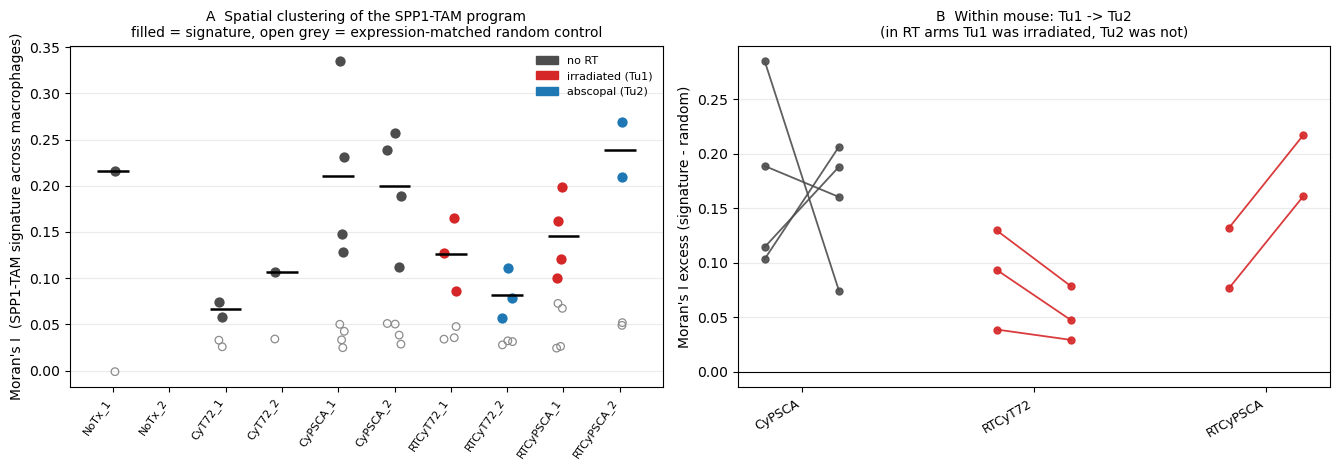

In [11]:
# ---- §A figure: Moran's I per tissue by arm, real vs random, + within-mouse Tu1->Tu2 ----
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
rng = np.random.default_rng(SEED)
xmap = {g: i for i, g in enumerate(GROUPS)}

ax = axes[0]
for g in GROUPS:
    s = piv[piv["cond"].astype(str) + "_" + piv["tumor_loc"].astype(str) == g]
    if s.empty:
        continue
    col = {"no_RT": NORT_C, "irradiated": RT_C, "abscopal": ABS_C}[s["rt_status"].iloc[0]]
    jit = rng.uniform(-0.13, 0.13, len(s))
    ax.scatter(xmap[g] + jit, s["I_spp1tam"], s=55, color=col, zorder=3, linewidths=0, label=None)
    ax.scatter(xmap[g] + jit, s["I_random"], s=30, facecolors="none", edgecolors="0.55",
               linewidths=0.9, zorder=2)
    ax.hlines(s["I_spp1tam"].mean(), xmap[g] - 0.28, xmap[g] + 0.28, color="k", lw=1.8, zorder=4)
ax.set_xticks(list(xmap.values())); ax.set_xticklabels(GROUPS, rotation=55, ha="right", fontsize=8)
ax.set_ylabel("Moran's I  (SPP1-TAM signature across macrophages)")
ax.set_title("A  Spatial clustering of the SPP1-TAM program\n"
             "filled = signature, open grey = expression-matched random control", fontsize=10)
ax.legend(handles=[Patch(color=NORT_C, label="no RT"), Patch(color=RT_C, label="irradiated (Tu1)"),
                   Patch(color=ABS_C, label="abscopal (Tu2)")], fontsize=8, frameon=False)
ax.grid(axis="y", alpha=0.25)

ax = axes[1]
w = piv.pivot_table(index=["cond", "mouse"], columns="tumor_loc", values="I_excess", observed=True)
w.columns = [f"Tu{c}" for c in w.columns]
w = w.reset_index().dropna(subset=[c for c in ["Tu1", "Tu2"] if c in w.columns])
present_conds = [c for c in COND_PRESENT if c in set(w["cond"].astype(str))]
for i, cnd in enumerate(present_conds):
    s = w[w["cond"].astype(str) == cnd]
    col = RT_C if COND_META.get(cnd, {}).get("RT") else NORT_C
    for _, r in s.iterrows():
        ax.plot([i - 0.16, i + 0.16], [r["Tu1"], r["Tu2"]], "-o", color=col, ms=5, lw=1.3, alpha=0.9)
ax.set_xticks(range(len(present_conds))); ax.set_xticklabels(present_conds, rotation=30, ha="right", fontsize=9)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("Moran's I excess (signature - random)")
ax.set_title("B  Within mouse: Tu1 -> Tu2\n(in RT arms Tu1 was irradiated, Tu2 was not)", fontsize=10)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout(); fig.savefig(FIG_DIR / "rt_moran_spp1tam.png", dpi=200, bbox_inches="tight")
plt.show(); plt.close(fig)

### 6b. Is the Moran's I difference just a density difference?

Macrophage density differs several-fold between arms (06), and kNN weights make Moran's I
scale-adaptive but not scale-free. If `I_excess` tracks `n_mac` or `knn_dist_um` across all
tissues, an arm difference is a density difference wearing a spatial label.

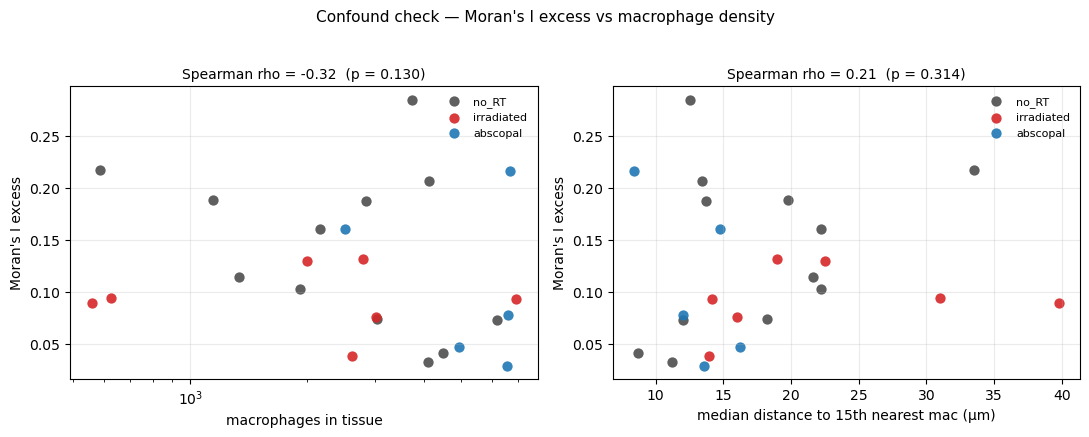

|rho| < ~0.4 -> density is not driving I_excess. Large |rho| -> report the arm difference
only alongside a density-matched subset, or drop the claim.


In [12]:
from scipy.stats import spearmanr as _spearman
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, xcol, xlab in [(axes[0], "n_mac", "macrophages in tissue"),
                       (axes[1], "knn_dist_um", "median distance to 15th nearest mac (µm)")]:
    for st, col in [("no_RT", NORT_C), ("irradiated", RT_C), ("abscopal", ABS_C)]:
        s = piv[piv["rt_status"] == st]
        ax.scatter(s[xcol], s["I_excess"], s=55, color=col, label=st, linewidths=0, alpha=0.9)
    ok = piv[[xcol, "I_excess"]].dropna()
    rho, p = _spearman(ok[xcol], ok["I_excess"]) if len(ok) > 4 else (np.nan, np.nan)
    ax.set_xlabel(xlab); ax.set_ylabel("Moran's I excess")
    ax.set_title(f"Spearman rho = {rho:.2f}  (p = {p:.3f})", fontsize=10)
    if xcol == "n_mac":
        ax.set_xscale("log")
    ax.grid(alpha=0.25); ax.legend(fontsize=8, frameon=False)
fig.suptitle("Confound check — Moran's I excess vs macrophage density", y=1.03, fontsize=11)
fig.tight_layout(); fig.savefig(FIG_DIR / "rt_moran_density_check.png", dpi=200, bbox_inches="tight")
plt.show(); plt.close(fig)
print("|rho| < ~0.4 -> density is not driving I_excess. Large |rho| -> report the arm difference")
print("only alongside a density-matched subset, or drop the claim.")

## 7. §B — Is the SPP1-TAM program more tightly *coupled* to the niche after RT?

Cross-set bivariate Moran's I at the 50 µm radius: rows are macrophages carrying `SPP1_TAM_sig`,
columns are the **non-myeloid** cells within 50 µm carrying each pathway score. This is the
statistic Aim 1 proposes, applied to the mouse data.

The contrast tier is the whole argument: if IFN-γ / TNF-α / inflammatory coupling moves as much
as the metabolic tier, then RT changed the tissue globally and none of this is niche-specific.

In [13]:
score_cols_full = [f"{c}_score" for c in path_cols]

rows = []
for ti, t in enumerate(TISSUES, 1):
    mask, xy = coords_um_for(adata, sdata, t)
    obs_t = adata.obs.loc[mask]
    mac_u   = obs_t["is_mac"].values.astype(bool)
    niche_u = obs_t["niche_cell"].values.astype(bool)
    if niche_u.sum() < 50:
        print(f"skip {t}: only {int(niche_u.sum())} niche cells"); continue
    m = tissue_meta.loc[t]
    sig = obs_t.loc[mac_u, "SPP1_TAM_sig"].to_numpy(float)
    mac_xy, niche_xy = xy[mac_u], xy[niche_u]
    rng = np.random.default_rng(SEED + 1000 + ti)
    for short in path_cols:
        y = obs_t.loc[niche_u, f"{short}_score"].to_numpy(float)
        res = cross_moran_bands(mac_xy, niche_xy, sig, y, [0, NICHE_RADIUS_UM],
                                n_perm=N_PERM, rng=rng)
        for r in res:
            rows.append({"tissue": t, "cond": m["cond"], "tumor_loc": m["tumor_loc"],
                         "mouse": m["mouse"], "cart": m["cart"], "rt_status": m["rt_status"],
                         "pathway": short, "label": LABEL_OF[short], "tier": TIER_OF[short], **r})
    print(f"[{ti}/{len(TISSUES)}] {t} coupling done", flush=True)

cross = pd.DataFrame(rows)
cross.to_csv(OUT_DIR / "rt_cross_moran_long.csv", index=False)

summ = (cross.groupby(["tier", "pathway", "label"], observed=True)
        .agg(n_tissues=("tissue", "count"), mean_I=("I_cross", "mean"), mean_r=("r_lag", "mean"),
             frac_pos=("r_lag", lambda s: float((s > 0).mean())),
             frac_p05=("p_perm", lambda s: float((s < 0.05).mean())))
        .reset_index())
summ["tier"] = pd.Categorical(summ["tier"], TIER_ORDER, ordered=True)
summ = summ.sort_values(["tier", "mean_r"], ascending=[True, False])
summ.to_csv(OUT_DIR / "rt_cross_moran_summary.csv", index=False)
print("\n=== baseline coupling across ALL tissues (sanity: should reproduce 02's rho ranking) ===")
print(summ.round(3).to_string(index=False))

[1/24] NoTx_1_1 coupling done


[2/24] CyT72_1_2 coupling done


[3/24] CyT72_1_4 coupling done


[4/24] CyT72_2_3 coupling done


[5/24] CyPSCA_1_1 coupling done


...

[21/24] RTCyPSCA_1_4 coupling done


[22/24] RTCyPSCA_1_5 coupling done


[23/24] RTCyPSCA_2_3 coupling done


[24/24] RTCyPSCA_2_4 coupling done



=== baseline coupling across ALL tissues (sanity: should reproduce 02's rho ranking) ===
     tier             pathway                           label  n_tissues  mean_I  mean_r  frac_pos  frac_p05
metabolic   Cholesterol_Homeo            Cholesterol handling         24   0.034   0.074     0.708     0.833
metabolic              OxPhos       Oxidative phosphorylation         24   0.026   0.062     0.708     0.625
metabolic   FA_Beta_Oxidation          Fatty acid β-oxidation         24   0.013   0.060     0.708     0.750
metabolic Lysosomal_Transport             Lysosomal transport         24   0.017   0.059     0.708     0.583
metabolic     Lipid_Oxidation                 Lipid oxidation         24   0.013   0.056     0.708     0.875
metabolic     FattyAcid_Metab           Fatty acid metabolism         24   0.017   0.045     0.667     0.625
metabolic    Scavenger_Uptake Scavenger-mediated lipid uptake         24   0.014   0.043     0.792     0.875
metabolic  Cholesterol_Efflux         

In [14]:
con_cross  = rt_contrasts(cross, "r_lag", group_cols=["pathway"])
con_cross["tier"]  = con_cross["pathway"].map(TIER_OF)
con_cross["label"] = con_cross["pathway"].map(LABEL_OF)
con_cross.to_csv(OUT_DIR / "rt_cross_moran_contrasts.csv", index=False)

cons_cross = consistency(con_cross, label_cols=["pathway"])
cons_cross["tier"]  = cons_cross["pathway"].map(TIER_OF)
cons_cross["label"] = cons_cross["pathway"].map(LABEL_OF)
cons_cross["tier"]  = pd.Categorical(cons_cross["tier"], TIER_ORDER, ordered=True)
cons_cross.to_csv(OUT_DIR / "rt_cross_moran_consistency.csv", index=False)

HEAD = "RT-direct vs no-RT   [Tu1, loc-matched]"
h = (cons_cross[cons_cross["contrast"] == HEAD]
     .sort_values(["tier", "mean_delta"], ascending=[True, False]))
print(f"=== §B  RT effect on SPP1-TAM <-> niche coupling  ({HEAD}) ===")
print("   delta = change in r_lag (coupling) when RT is added on top of Cy + CAR-T\n")
print(h[["tier", "label", "delta_PSCA", "delta_nonspecific", "mean_delta", "sign_agree"]]
      .round(3).to_string(index=False))
print("\nby tier — mean delta across pathways (the specificity test):")
print(h.groupby("tier", observed=True)["mean_delta"].agg(["mean", "count"]).round(3).to_string())
print("\n  metabolic/damage tiers UP and the contrast tier flat-or-down  -> RT tightened the")
print("  SPP1-TAM/lipid-damage niche specifically. All three tiers moving together -> artifact.")
print("\n=== the other contrasts, same metric ===")
for cname in [c[0] for c in CONTRAST_SPECS if c[0] != HEAD]:
    d = cons_cross[cons_cross["contrast"] == cname]
    if d.empty:
        continue
    print(f"\n{cname}:")
    print(d.groupby("tier", observed=True)["mean_delta"].agg(["mean", "count"]).round(3).to_string())

=== §B  RT effect on SPP1-TAM <-> niche coupling  (RT-direct vs no-RT   [Tu1, loc-matched]) ===
   delta = change in r_lag (coupling) when RT is added on top of Cy + CAR-T

     tier                           label  delta_PSCA  delta_nonspecific  mean_delta  sign_agree
metabolic      Lipid droplet organization       0.032              0.020       0.026        True
metabolic       Oxidative phosphorylation       0.060             -0.009       0.025       False
metabolic                 Lipid oxidation       0.061             -0.020       0.021       False
metabolic           Fatty acid metabolism       0.037             -0.008       0.014       False
metabolic            Cholesterol handling       0.027             -0.022       0.003       False
metabolic           Oxidized LDL response       0.009             -0.016      -0.003       False
metabolic          Fatty acid β-oxidation       0.012             -0.022      -0.005       False
metabolic             Lysosomal transport      -0.0

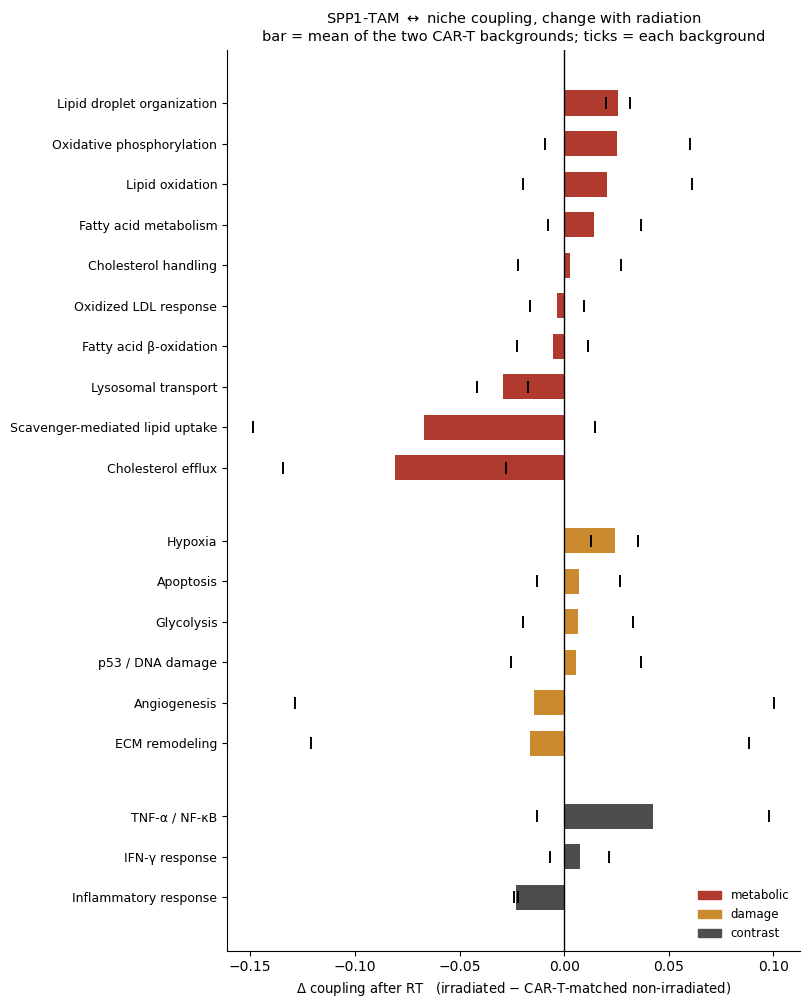

In [15]:
# ---- §B figure: RT effect per pathway, one bar per CAR-T background, grouped by tier ----
h2 = h.dropna(subset=["mean_delta"]).copy()
h2 = h2.sort_values(["tier", "mean_delta"], ascending=[True, False])   # largest effect at top
TIER_C = {"metabolic": "#B03A2E", "damage": "#CA8A2E", "contrast": "#4d4d4d"}

y, ytick, ylab, gap = [], [], [], 0.0
for tier in TIER_ORDER:
    sub = h2[h2["tier"] == tier]
    for _, r in sub.iterrows():
        y.append(gap); ytick.append(gap); ylab.append(r["label"]); gap += 1.0
    if len(sub):
        gap += 0.8
h2 = h2.assign(_y=y)

fig, ax = plt.subplots(figsize=(8.2, 0.42 * len(h2) + 2.2))
ax.barh(h2["_y"], h2["mean_delta"], height=0.62,
        color=[TIER_C[t] for t in h2["tier"]], zorder=2)
for _, r in h2.iterrows():                                    # each background as a tick mark
    for v, mk in [(r["delta_PSCA"], "|"), (r["delta_nonspecific"], "|")]:
        if np.isfinite(v):
            ax.plot([v], [r["_y"]], mk, color="k", ms=9, mew=1.4, zorder=4)
ax.axvline(0, color="k", lw=1, zorder=3)
ax.set_yticks(ytick); ax.set_yticklabels(ylab, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("$\\Delta$ coupling after RT   (irradiated $-$ CAR-T-matched non-irradiated)", fontsize=9.5)
ax.set_title("SPP1-TAM $\\leftrightarrow$ niche coupling, change with radiation\n"
             "bar = mean of the two CAR-T backgrounds; ticks = each background", fontsize=10.5)
ax.legend(handles=[Patch(color=TIER_C[t], label=t) for t in TIER_ORDER],
          fontsize=8.5, loc="lower right", frameon=False)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig(FIG_DIR / "rt_cross_moran_effect.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "rt_cross_moran_effect.pdf", bbox_inches="tight")
plt.show(); plt.close(fig)

## 8. §C — Over what distance does the coupling hold, and does RT change that scale?

The same statistic in concentric annuli (0-25, 25-50, 50-100, 100-150 µm) — a **cross-correlogram**,
which is the discrete cousin of the cross-variogram proposed in Aim 1. A real niche gives a curve
that decays with distance; a flat curve means the association is a whole-tissue property and the
word "niche" is not earned. Macrophages are subsampled to `MAX_MACS_FOR_BANDS` per tissue to keep
the 150 µm neighbour graph small.

In [16]:
BAND_PATHWAYS = [p for p in ["oxLDL_Response", "Cholesterol_Homeo", "Hypoxia", "ECM",
                             "OxPhos", "IFN_gamma"] if p in path_cols]
print("band analysis on:", [LABEL_OF[p] for p in BAND_PATHWAYS])

rows = []
for ti, t in enumerate(TISSUES, 1):
    mask, xy = coords_um_for(adata, sdata, t)
    obs_t = adata.obs.loc[mask]
    mac_u   = obs_t["is_mac"].values.astype(bool)
    niche_u = obs_t["niche_cell"].values.astype(bool)
    if niche_u.sum() < 50:
        continue
    m = tissue_meta.loc[t]
    rng = np.random.default_rng(SEED + 2000 + ti)
    sig = obs_t.loc[mac_u, "SPP1_TAM_sig"].to_numpy(float)
    mac_xy = xy[mac_u]
    if len(mac_xy) > MAX_MACS_FOR_BANDS:                      # subsample macs, keep all niche cells
        sel = rng.choice(len(mac_xy), MAX_MACS_FOR_BANDS, replace=False)
        mac_xy, sig = mac_xy[sel], sig[sel]
    niche_xy = xy[niche_u]
    for short in BAND_PATHWAYS:
        y = obs_t.loc[niche_u, f"{short}_score"].to_numpy(float)
        for r in cross_moran_bands(mac_xy, niche_xy, sig, y, BAND_EDGES_UM,
                                   n_perm=199, rng=rng, min_units=100):
            rows.append({"tissue": t, "cond": m["cond"], "tumor_loc": m["tumor_loc"],
                         "cart": m["cart"], "rt_status": m["rt_status"], "pathway": short,
                         "label": LABEL_OF[short], "tier": TIER_OF[short], **r})
    print(f"[{ti}/{len(TISSUES)}] {t} bands done", flush=True)

bands = pd.DataFrame(rows)
bands.to_csv(OUT_DIR / "rt_cross_moran_bands_long.csv", index=False)

band_summ = (bands.groupby(["pathway", "label", "tier", "band", "band_lo", "rt_status"], observed=True)
             .agg(n=("tissue", "count"), mean_r=("r_lag", "mean"),
                  sem_r=("r_lag", lambda s: float(s.std(ddof=1) / max(np.sqrt(len(s)), 1))))
             .reset_index().sort_values(["pathway", "band_lo"]))
band_summ.to_csv(OUT_DIR / "rt_cross_moran_bands_summary.csv", index=False)
print("\n=== coupling by distance band and RT status ===")
print(band_summ.pivot_table(index=["tier", "label", "band"], columns="rt_status",
                            values="mean_r", observed=True).round(3).to_string())

band analysis on: ['Oxidized LDL response', 'Cholesterol handling', 'Hypoxia', 'ECM remodeling', 'Oxidative phosphorylation', 'IFN-γ response']


[1/24] NoTx_1_1 bands done


[2/24] CyT72_1_2 bands done


[3/24] CyT72_1_4 bands done


[4/24] CyT72_2_3 bands done


...

[21/24] RTCyPSCA_1_4 bands done


[22/24] RTCyPSCA_1_5 bands done


[23/24] RTCyPSCA_2_3 bands done


[24/24] RTCyPSCA_2_4 bands done



=== coupling by distance band and RT status ===
rt_status                                    abscopal  irradiated  no_RT
tier      label                     band                                
contrast  IFN-γ response            0-25       -0.129      -0.111 -0.108
                                    100-150    -0.057      -0.068 -0.009
                                    25-50      -0.117      -0.117 -0.095
                                    50-100     -0.098      -0.103 -0.072
damage    ECM remodeling            0-25        0.133       0.096  0.140
                                    100-150     0.057       0.059 -0.014
                                    25-50       0.127       0.085  0.110
                                    50-100      0.072       0.102  0.059
          Hypoxia                   0-25        0.126       0.098  0.044
                                    100-150     0.095       0.066 -0.015
                                    25-50       0.119       0.104  0.046
  

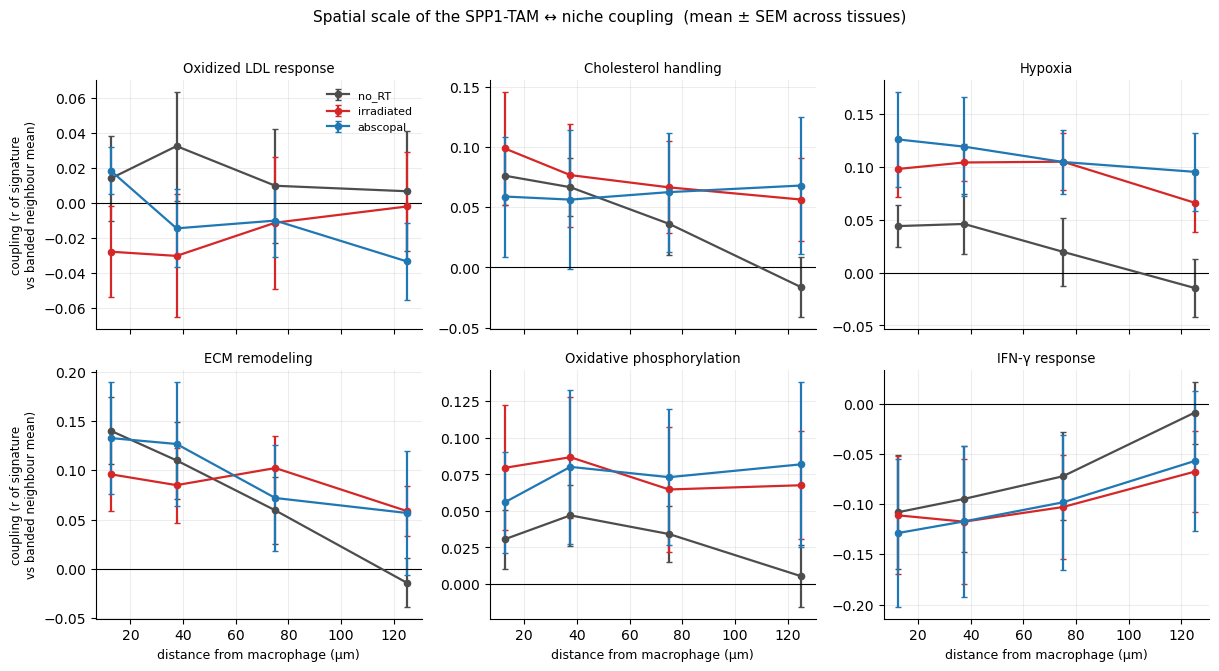

In [17]:
ncol = min(3, len(BAND_PATHWAYS))
nrow = int(np.ceil(len(BAND_PATHWAYS) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.1 * ncol, 3.3 * nrow), squeeze=False, sharex=True)
xs = [0.5 * (lo + hi) for lo, hi in zip(BAND_EDGES_UM[:-1], BAND_EDGES_UM[1:])]
for ax, short in zip(axes.ravel(), BAND_PATHWAYS):
    d = band_summ[band_summ["pathway"] == short]
    for st, col in [("no_RT", NORT_C), ("irradiated", RT_C), ("abscopal", ABS_C)]:
        s = d[d["rt_status"] == st].sort_values("band_lo")
        if s.empty:
            continue
        ax.errorbar(xs[:len(s)], s["mean_r"], yerr=s["sem_r"], marker="o", ms=4.5, lw=1.6,
                    capsize=2.5, color=col, label=st)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(LABEL_OF[short], fontsize=9.5)
    ax.grid(alpha=0.22)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
for ax in axes.ravel()[len(BAND_PATHWAYS):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("distance from macrophage (µm)", fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("coupling (r of signature\nvs banded neighbour mean)", fontsize=8.5)
axes[0, 0].legend(fontsize=8, frameon=False)
fig.suptitle("Spatial scale of the SPP1-TAM ↔ niche coupling  (mean ± SEM across tissues)",
             y=1.01, fontsize=11)
fig.tight_layout(); fig.savefig(FIG_DIR / "rt_cross_moran_bands.png", dpi=300, bbox_inches="tight")
plt.show(); plt.close(fig)

## 9. §D — Do the macrophages themselves shift metabolically after RT?

The most direct reading of *"something increases in SPP1-TAMs after radiation"*, and the mouse
counterpart of the human 8 Gy-vs-sham panel. Per tissue, the mean pathway score in

- **all macrophages**, and
- the **SPP1-TAM-high** macrophages (top quartile of the signature, cut pooled across all macs so
  a cell's call does not depend on which tissue it came from — the same convention as 07), and
- `mac_minus_niche`: the macrophage mean minus the non-myeloid mean of the *same tissue*, which
  cancels tissue-level depth and normalisation shifts and is the number to trust for an arm
  comparison.

No circularity here: the comparison is RT vs no-RT within one cell class, not high-vs-low
signature (which is what 01c already did in single cell).

In [18]:
mac_all_sig = adata.obs.loc[adata.obs["is_mac"], "SPP1_TAM_sig"]
SIG_CUT = float(mac_all_sig.quantile(0.75))
adata.obs["tam_high"] = adata.obs["is_mac"].values & (adata.obs["SPP1_TAM_sig"].values >= SIG_CUT)
print(f"SPP1-TAM-high cut = {SIG_CUT:.3f} (top 25% of pooled macs; "
      f"{int(adata.obs['tam_high'].sum()):,} cells)")

rows = []
for t in TISSUES:
    obs_t = adata.obs.loc[adata.obs[TISSUE_COL].astype(str).eq(t)]
    m = tissue_meta.loc[t]
    mac_u   = obs_t["is_mac"].values.astype(bool)
    high_u  = obs_t["tam_high"].values.astype(bool)
    niche_u = obs_t["niche_cell"].values.astype(bool)
    if high_u.sum() < 30 or niche_u.sum() < 50:
        print(f"skip {t}: tam_high={int(high_u.sum())} niche={int(niche_u.sum())}"); continue
    for short in path_cols:
        v = obs_t[f"{short}_score"].to_numpy(float)
        rows.append({"tissue": t, "cond": m["cond"], "tumor_loc": m["tumor_loc"],
                     "mouse": m["mouse"], "cart": m["cart"], "rt_status": m["rt_status"],
                     "pathway": short, "label": LABEL_OF[short], "tier": TIER_OF[short],
                     "n_mac": int(mac_u.sum()), "n_tam_high": int(high_u.sum()),
                     "mac_mean": float(v[mac_u].mean()),
                     "tamhigh_mean": float(v[high_u].mean()),
                     "niche_mean": float(v[niche_u].mean()),
                     "mac_minus_niche": float(v[mac_u].mean() - v[niche_u].mean()),
                     "tamhigh_minus_niche": float(v[high_u].mean() - v[niche_u].mean())})
macpath = pd.DataFrame(rows)
macpath.to_csv(OUT_DIR / "rt_mac_pathway_long.csv", index=False)

frames = []
for metric in ["mac_minus_niche", "tamhigh_minus_niche", "mac_mean", "tamhigh_mean"]:
    c = rt_contrasts(macpath, metric, group_cols=["pathway"])
    if c.empty:
        continue
    k = consistency(c, label_cols=["pathway"]); k["metric"] = metric
    frames.append(k)
cons_mac = pd.concat(frames, ignore_index=True)
cons_mac["tier"]  = cons_mac["pathway"].map(TIER_OF)
cons_mac["label"] = cons_mac["pathway"].map(LABEL_OF)
cons_mac["tier"]  = pd.Categorical(cons_mac["tier"], TIER_ORDER, ordered=True)
cons_mac.to_csv(OUT_DIR / "rt_mac_pathway_consistency.csv", index=False)

for metric in ["tamhigh_minus_niche", "mac_minus_niche"]:
    d = (cons_mac[(cons_mac["contrast"] == HEAD) & (cons_mac["metric"] == metric)]
         .sort_values(["tier", "mean_delta"], ascending=[True, False]))
    if d.empty:
        continue
    print(f"\n=== §D  RT effect on {metric}   ({HEAD}) ===")
    print(d[["tier", "label", "delta_PSCA", "delta_nonspecific", "mean_delta", "sign_agree"]]
          .round(4).to_string(index=False))
    print("by tier:")
    print(d.groupby("tier", observed=True)["mean_delta"].agg(["mean", "count"]).round(4).to_string())

SPP1-TAM-high cut = 0.505 (top 25% of pooled macs; 20,392 cells)



=== §D  RT effect on tamhigh_minus_niche   (RT-direct vs no-RT   [Tu1, loc-matched]) ===
     tier                           label  delta_PSCA  delta_nonspecific  mean_delta  sign_agree
metabolic Scavenger-mediated lipid uptake     -0.0088             0.0449      0.0180       False
metabolic              Cholesterol efflux      0.0004             0.0084      0.0044        True
metabolic           Oxidized LDL response     -0.0075            -0.0092     -0.0083        True
metabolic                 Lipid oxidation     -0.0049            -0.0135     -0.0092        True
metabolic          Fatty acid β-oxidation     -0.0121            -0.0084     -0.0103        True
metabolic      Lipid droplet organization     -0.0175            -0.0118     -0.0147        True
metabolic             Lysosomal transport     -0.0050            -0.0264     -0.0157        True
metabolic           Fatty acid metabolism     -0.0064            -0.0303     -0.0183        True
metabolic       Oxidative phosphoryla

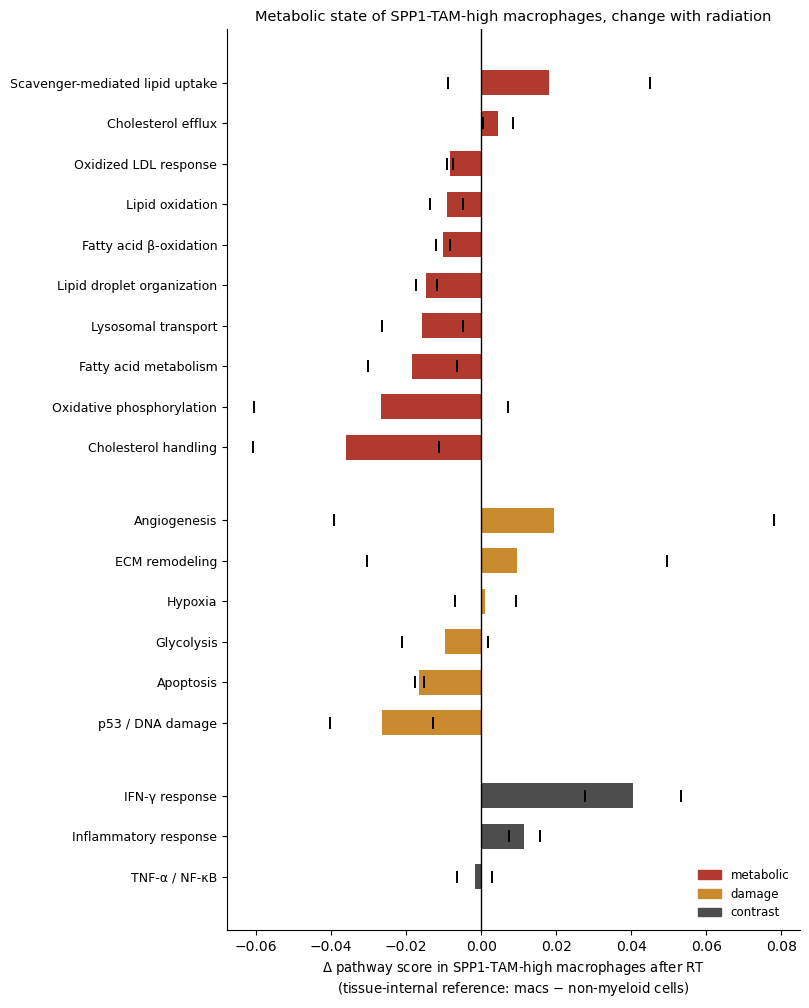

In [19]:
# ---- §D figure: pathway activity in SPP1-TAM-high macs, irradiated vs matched non-irradiated ----
d = (cons_mac[(cons_mac["contrast"] == HEAD) & (cons_mac["metric"] == "tamhigh_minus_niche")]
     .dropna(subset=["mean_delta"]).sort_values(["tier", "mean_delta"], ascending=[True, False]))
y, ytick, ylab, gap = [], [], [], 0.0
for tier in TIER_ORDER:
    sub = d[d["tier"] == tier]
    for _, r in sub.iterrows():
        y.append(gap); ytick.append(gap); ylab.append(r["label"]); gap += 1.0
    if len(sub):
        gap += 0.8
d = d.assign(_y=y)

fig, ax = plt.subplots(figsize=(8.2, 0.42 * len(d) + 2.2))
ax.barh(d["_y"], d["mean_delta"], height=0.62, color=[TIER_C[t] for t in d["tier"]], zorder=2)
for _, r in d.iterrows():
    for v in (r["delta_PSCA"], r["delta_nonspecific"]):
        if np.isfinite(v):
            ax.plot([v], [r["_y"]], "|", color="k", ms=9, mew=1.4, zorder=4)
ax.axvline(0, color="k", lw=1, zorder=3)
ax.set_yticks(ytick); ax.set_yticklabels(ylab, fontsize=9); ax.invert_yaxis()
ax.set_xlabel("$\\Delta$ pathway score in SPP1-TAM-high macrophages after RT\n"
              "(tissue-internal reference: macs $-$ non-myeloid cells)", fontsize=9.5)
ax.set_title("Metabolic state of SPP1-TAM-high macrophages, change with radiation", fontsize=10.5)
ax.legend(handles=[Patch(color=TIER_C[t], label=t) for t in TIER_ORDER],
          fontsize=8.5, loc="lower right", frameon=False)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig(FIG_DIR / "rt_mac_pathway_effect.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "rt_mac_pathway_effect.pdf", bbox_inches="tight")
plt.show(); plt.close(fig)

## 10. §E — The verdict

Which of the three readouts actually moved up after RT, in both CAR-T backgrounds, with its
control staying put. Anything that fails the control column is not usable in the proposal.

In [20]:
def _line(name, delta, agree, control_note):
    arrow = "UP  " if (np.isfinite(delta) and delta > 0) else ("DOWN" if np.isfinite(delta) else "n/a ")
    flag  = "consistent in BOTH backgrounds" if agree else "backgrounds DISAGREE - not usable"
    return f"  {name:<46s} {arrow} {delta:+.4f}   {flag}\n      control: {control_note}"

verdict = []

# A — Moran's I excess
a = cons_moran[cons_moran["contrast"] == HEAD]
if not a.empty:
    r = a.iloc[0]
    dr = comp.loc[comp["contrast"] == HEAD, "d_random"]
    ctrl = (f"random-signature Moran's I moved {float(dr.iloc[0]):+.4f} "
            f"({'small vs the signature - specific' if len(dr) and abs(float(dr.iloc[0])) < abs(r['mean_delta']) / 2 else 'COMPARABLE - do not claim specificity'})")
    verdict.append(_line("A. spatial clustering (Moran's I excess)", r["mean_delta"], r["sign_agree"], ctrl))

# B / D — tier means, with the contrast tier as the control
for tag, frame, metric in [("B. coupling to the niche (cross-Moran)", cons_cross, None),
                           ("D. metabolic state of SPP1-TAM-high macs",
                            cons_mac[cons_mac["metric"] == "tamhigh_minus_niche"], "tamhigh_minus_niche")]:
    d = frame[frame["contrast"] == HEAD]
    if d.empty:
        continue
    tm = d.groupby("tier", observed=True)["mean_delta"].mean()
    agree_metab = bool(d.loc[d["tier"] == "metabolic", "sign_agree"].mean() > 0.5)
    ctrl = (f"contrast tier moved {tm.get('contrast', np.nan):+.4f} vs metabolic "
            f"{tm.get('metabolic', np.nan):+.4f}")
    verdict.append(_line(tag, float(tm.get("metabolic", np.nan)), agree_metab, ctrl))

top_up = (cons_cross[(cons_cross["contrast"] == HEAD) & cons_cross["sign_agree"]
                     & (cons_cross["tier"] != "contrast")]
          .nlargest(5, "mean_delta")[["label", "mean_delta"]])
top_mac = (cons_mac[(cons_mac["contrast"] == HEAD) & (cons_mac["metric"] == "tamhigh_minus_niche")
                    & cons_mac["sign_agree"] & (cons_mac["tier"] != "contrast")]
           .nlargest(5, "mean_delta")[["label", "mean_delta"]])

print(f"""
==================== SUMMARY — report these back ====================
CONTRAST : "{HEAD}"  = adding RT on top of Cy + CAR-T, run separately in the
           PSCA and TAG72 backgrounds. There is no RT-alone arm; this is the strongest RT
           contrast the mouse design supports.
TISSUES  : {len(TISSUES)} usable of {len(qc_tissue)} (>= {MIN_MACS_FOR_MORAN} macs)
           {qc_tissue[qc_tissue['usable']].groupby('rt_status', observed=True).size().to_dict()}

WHAT MOVED AFTER RT
{chr(10).join(verdict)}

Top pathways whose SPP1-TAM COUPLING rose with RT in both backgrounds:
{top_up.round(4).to_string(index=False) if len(top_up) else '  (none consistent in both backgrounds)'}

Top pathways whose activity rose INSIDE SPP1-TAM-high macrophages in both backgrounds:
{top_mac.round(4).to_string(index=False) if len(top_mac) else '  (none consistent in both backgrounds)'}

HOW TO READ THIS
 1. Nothing here is a p-value claim. n = 2-4 tissues per side. The evidence is (a) the sign
    agreeing across two independent CAR-T backgrounds, (b) the control not moving, and
    (c) the distance-band curve in §C decaying rather than staying flat.
 2. §A's control is the random signature; §B/§D's control is the contrast tier. A readout whose
    control moved with it says "irradiated tissue is different", not "SPP1-TAMs are different",
    and must not go in the proposal.
 3. If §B rose while §A did not, the story is COUPLING (the program is no better clustered, but it
    now tracks the damage/lipid niche) — which is still exactly Aim 1's thesis, and is the
    honest way to word it.
 4. §C is the figure that motivates the cross-variogram in Aim 1: it shows the coupling has a
    finite spatial range, which is the thing hotspot/neighbourhood analysis cannot establish.
 5. Cross-check against the human 8 Gy-vs-sham panel: OxPhos / fatty-acid metabolism UP and
    IFN-γ DOWN in both species would let the proposal claim the finding is conserved.

CAVEATS
 - RT is confounded with nothing here except that it is always given WITH Cy + CAR-T; the
   baseline arms received the same Cy + CAR-T, so the contrast is clean for "adding RT".
 - NoTx is not usable spatially (7/8 tissues < 50 macs), so no untreated baseline exists here.
 - Moran's I uses kNN weights, so it is density-adaptive but not density-free — §6b is the check.
 - Underpowered pathways are listed in rt_effect_pathway_qc.csv; a null there means nothing.

FILES WRITTEN -> {OUT_DIR}
  rt_effect_tissue_qc.csv / rt_effect_pathway_qc.csv
  rt_moran_spp1tam_long.csv / rt_moran_spp1tam_per_tissue.csv / rt_moran_contrasts.csv
  rt_cross_moran_long.csv / rt_cross_moran_summary.csv / rt_cross_moran_contrasts.csv
  rt_cross_moran_consistency.csv / rt_cross_moran_bands_long.csv / rt_cross_moran_bands_summary.csv
  rt_mac_pathway_long.csv / rt_mac_pathway_consistency.csv
FIGURES -> {FIG_DIR}
  rt_moran_spp1tam.png, rt_moran_density_check.png, rt_cross_moran_effect.png/.pdf,
  rt_cross_moran_bands.png, rt_mac_pathway_effect.png/.pdf
=====================================================================
""")


==================== SUMMARY — report these back ====================
CONTRAST : "RT-direct vs no-RT   [Tu1, loc-matched]"  = adding RT on top of Cy + CAR-T, run separately in the
           PSCA and TAG72 backgrounds. There is no RT-alone arm; this is the strongest RT
           contrast the mouse design supports.
TISSUES  : 24 usable of 32 (>= 150 macs)
           {'abscopal': 5, 'irradiated': 7, 'no_RT': 12}

WHAT MOVED AFTER RT
  A. spatial clustering (Moran's I excess)       DOWN -0.0125   backgrounds DISAGREE - not usable
      control: random-signature Moran's I moved +0.0099 (COMPARABLE - do not claim specificity)
  B. coupling to the niche (cross-Moran)         DOWN -0.0098   backgrounds DISAGREE - not usable
      control: contrast tier moved +0.0089 vs metabolic -0.0098
  D. metabolic state of SPP1-TAM-high macs       DOWN -0.0117   consistent in BOTH backgrounds
      control: contrast tier moved +0.0168 vs metabolic -0.0117

Top pathways whose SPP1-TAM COUPLING rose with 

## 11. §G — Diagnostics dump (run this and paste the whole output back)

Reads only the CSVs §A-§D already wrote — no recomputation, runs in seconds. It answers the four
questions the SUMMARY block cannot:

1. **Is the metabolic panel powered at all in spatial?** A null on an underpowered set is not a
   null. This is the one thing that could overturn the negative result.
2. **What does the tightest RT contrast say?** `RT-direct vs RT-abscopal [within arm]` is the same
   animal, same drugs, only local irradiation differs — a cleaner RT test than the headline.
3. **Does the coupling exist and decay with distance, regardless of RT?** That is the Aim 1
   preliminary figure, and it does not depend on the RT result at all.
4. **Is §A contaminated by macrophage density?**

In [21]:
# %% -- §G diagnostics: everything needed to decide whether the negative result is real --
import pandas as pd, numpy as np
from pathlib import Path
from scipy.stats import spearmanr

OUT = Path("/coh_labs/yunroseli/Jona/CAR-T/results/spp1_analysis")
pd.set_option("display.max_rows", 200); pd.set_option("display.width", 240)
_load = lambda n: pd.read_csv(OUT / n) if (OUT / n).exists() else None

print("=" * 78)
print("1. PATHWAY POWER — is a null even interpretable?")
print("=" * 78)
q = _load("rt_effect_pathway_qc.csv")
if q is not None:
    q = q.sort_values(["tier", "genes_det_gt10pct"], ascending=[True, False])
    print(q.round(2).to_string(index=False))
    weak = q[(q["genes_det_gt10pct"] < 10) | (q["score_IQR"] < 0.08)]
    print(f"\nUNDERPOWERED (<10 genes detected >10%, or score IQR <0.08): "
          f"{weak['pathway'].tolist() if len(weak) else 'none'}")
    print("A null on any of those says nothing. If most of the metabolic tier is here,")
    print("the negative result is a measurement limit, not a biological one.")

print("\n" + "=" * 78)
print("2. BASELINE COUPLING — does the niche association exist in the mouse at all?")
print("=" * 78)
s = _load("rt_cross_moran_summary.csv")
if s is not None:
    print(s.round(3).to_string(index=False))
    print("\nmean_r > 0 with frac_pos >= 0.7 = the coupling is real and consistent across tissues,")
    print("independent of anything RT does. This is the Aim 1 figure.")

print("\n" + "=" * 78)
print("3. EVERY RT CONTRAST, per pathway (not just the headline)")
print("=" * 78)
c = _load("rt_cross_moran_consistency.csv")
if c is not None:
    for name, d in c.groupby("contrast", observed=True):
        d = d.sort_values("mean_delta", ascending=False)
        n_agree = int(d["sign_agree"].sum())
        print(f"\n--- {name}   ({n_agree}/{len(d)} pathways sign-consistent) ---")
        print(d[["tier", "label", "delta_PSCA", "delta_nonspecific", "mean_delta",
                 "n_backgrounds", "sign_agree"]].round(4).to_string(index=False))
        t = d.groupby("tier", observed=True)["mean_delta"].agg(["mean", "count"])
        print("  tier means:", {k: round(v, 4) for k, v in t["mean"].items()})

print("\n" + "=" * 78)
print("4. SPATIAL SCALE — does the coupling decay with distance? (Aim 1's cross-variogram)")
print("=" * 78)
b = _load("rt_cross_moran_bands_summary.csv")
if b is not None:
    piv = b.pivot_table(index=["tier", "label", "band"], columns="rt_status",
                        values="mean_r", observed=True)
    print(piv.round(4).to_string())
    # decay MUST be computed within an rt_status — pooling first/last across statuses compares
    # one arm's near field to another arm's far field, which is meaningless.
    print("\n--- decay per pathway PER RT STATUS: |near field| -> |far field| ---")
    bb = b.sort_values("band_lo")
    dec = (bb.groupby(["tier", "label", "rt_status"], observed=True)["mean_r"]
           .agg(nearest="first", farthest="last").reset_index())
    dec["decay_abs"] = dec["nearest"].abs() - dec["farthest"].abs()
    dec["pct_lost"] = 100 * dec["decay_abs"] / dec["nearest"].abs().replace(0, np.nan)
    print(dec.round(3).to_string(index=False))
    print("\n--- % of the near-field coupling lost by 100-150 um, by RT status ---")
    print(dec.pivot_table(index=["tier", "label"], columns="rt_status", values="pct_lost",
                          observed=True).round(0).to_string())
    print("\nLarge positive decay = a finite-range niche (the claim Aim 1 needs).")
    print("decay ~ 0 = the association is a whole-tissue property; 'niche' is not earned.")

print("\n" + "=" * 78)
print("5. §A CONFOUND + baseline clustering")
print("=" * 78)
p = _load("rt_moran_spp1tam_per_tissue.csv")
if p is not None:
    for xcol in ["n_mac", "knn_dist_um"]:
        ok = p[[xcol, "I_excess"]].dropna()
        if len(ok) > 4:
            rho, pv = spearmanr(ok[xcol], ok["I_excess"])
            print(f"  I_excess vs {xcol:<14s}: Spearman rho = {rho:+.3f}  (p = {pv:.3f})")
    print(f"\n  baseline Moran's I of the signature : {p['I_spp1tam'].mean():.3f} "
          f"(random control {p['I_random'].mean():.3f}, excess {p['I_excess'].mean():.3f})")
    print("  A large positive excess means the program IS spatially clustered — worth reporting")
    print("  on its own even though RT does not change it.")
    print("\n  per RT status:")
    print(p.groupby("rt_status", observed=True)[["I_spp1tam", "I_random", "I_excess"]]
          .agg(["mean", "count"]).round(3).to_string())

print("\n" + "=" * 78)
print("6. MACROPHAGE-INTRINSIC, all contrasts")
print("=" * 78)
m = _load("rt_mac_pathway_consistency.csv")
if m is not None:
    mm = m[m["metric"] == "tamhigh_minus_niche"]
    for name, d in mm.groupby("contrast", observed=True):
        d = d.sort_values("mean_delta", ascending=False)
        print(f"\n--- {name}  ({int(d['sign_agree'].sum())}/{len(d)} sign-consistent) ---")
        print(d[["tier", "label", "delta_PSCA", "delta_nonspecific", "mean_delta", "sign_agree"]]
              .round(4).to_string(index=False))
print("\n" + "=" * 78)

1. PATHWAY POWER — is a null even interpretable?

2. BASELINE COUPLING — does the niche association exist in the mouse at all?

3. EVERY RT CONTRAST, per pathway (not just the headline)

4. SPATIAL SCALE — does the coupling decay with distance? (Aim 1's cross-variogram)

5. §A CONFOUND + baseline clustering

6. MACROPHAGE-INTRINSIC, all contrasts



## 12. §H — The control that decides the spatial-range result

§C's corrected decay table says the SPP1-TAM↔niche coupling **falls to ~zero by 100-150 µm in
non-irradiated tumours but persists in RT animals** (82% of the near-field coupling lost in
`no_RT`, 34% in `irradiated`, 15% in `abscopal`) — consistently across all five measurable
pathways. That is the only positive RT-associated finding in this notebook.

It has one serious alternative explanation. If irradiated tissue is architecturally **coarser** —
larger necrotic, fibrotic, or hypoxic zones — then *every* transcriptional field would correlate
over longer distances there, and the longer range would be a property of the tissue, not of the
SPP1-TAM program. §A already hinted at this: the random-signature Moran's I moved +0.0099 with RT,
comparable to the signature's own change.

So: **rerun §C with the expression-matched random signature in place of `SPP1_TAM_sig`**, same
tissues, same pathways, same bands.

- random signature also shows a longer range in RT tissue → architecture. The finding dies.
- random signature stays short-range while the real one extends → the range extension is specific
  to the SPP1-TAM program, and it is a real, reportable, Aim-1-shaped result.

Two supporting notes for interpreting the outcome. First, the bias runs *against* the finding:
irradiated tumours have lower macrophage density (06), and sparser sampling makes the banded
neighbour mean noisier, which attenuates `r_lag` toward zero — the observed direction is the
opposite of that bias. Second, **abscopal ≈ irradiated ≫ no_RT** across every pathway, and abscopal
tumours were never irradiated — so if this survives, it is a *systemic* effect of the animal having
received RT, not a local dose effect, and it must be worded that way.

control signature: rand_sig0  |  pathways: ['Oxidized LDL response', 'Cholesterol handling', 'Hypoxia', 'ECM remodeling', 'Oxidative phosphorylation', 'IFN-γ response']


[1/24] NoTx_1_1 control bands done


[2/24] CyT72_1_2 control bands done


[3/24] CyT72_1_4 control bands done


[4/24] CyT72_2_3 control bands done


...

[21/24] RTCyPSCA_1_4 control bands done


[22/24] RTCyPSCA_1_5 control bands done


[23/24] RTCyPSCA_2_3 control bands done


[24/24] RTCyPSCA_2_4 control bands done



=== % of near-field coupling lost by the outermost band ===
signature                 SPP1_TAM                  random_control                  
rt_status                 abscopal irradiated no_RT       abscopal irradiated  no_RT
label                                                                               
Cholesterol handling         -15.0       43.0  79.0           24.0       12.0   78.0
ECM remodeling                57.0       39.0  90.0           34.0       45.0   72.0
Hypoxia                       24.0       33.0  67.0           85.0       54.0   89.0
IFN-γ response                56.0       39.0  92.0         -131.0       23.0   84.0
Oxidative phosphorylation    -47.0       15.0  82.0           69.0       61.0 -238.0
Oxidized LDL response        -80.0       93.0  52.0          -25.0      -44.0   66.0

=== mean across pathways ===
signature       rt_status 
SPP1_TAM        abscopal      -1.0
                irradiated    44.0
                no_RT         77.0
random_contr

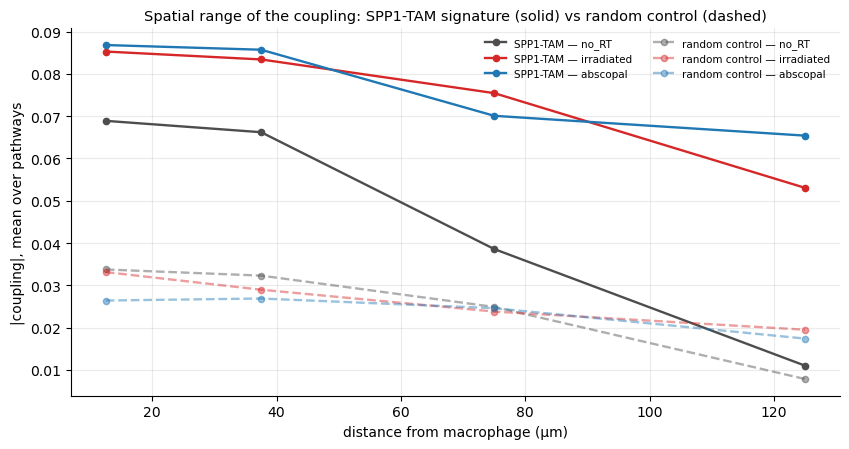

In [22]:
# %% -- §H: is the longer spatial range specific to the SPP1-TAM program, or just coarser tissue? --
CTRL_COL = RAND_COLS[0]        # expression-decile-matched random signature from §4b
print(f"control signature: {CTRL_COL}  |  pathways: {[LABEL_OF[p] for p in BAND_PATHWAYS]}")

rows = []
for ti, t in enumerate(TISSUES, 1):
    mask, xy = coords_um_for(adata, sdata, t)
    obs_t = adata.obs.loc[mask]
    mac_u, niche_u = obs_t["is_mac"].values.astype(bool), obs_t["niche_cell"].values.astype(bool)
    if niche_u.sum() < 50:
        continue
    m = tissue_meta.loc[t]
    rng = np.random.default_rng(SEED + 3000 + ti)
    ctrl = obs_t.loc[mac_u, CTRL_COL].to_numpy(float)
    mac_xy = xy[mac_u]
    if len(mac_xy) > MAX_MACS_FOR_BANDS:                 # identical subsample rule to §C
        sel = rng.choice(len(mac_xy), MAX_MACS_FOR_BANDS, replace=False)
        mac_xy, ctrl = mac_xy[sel], ctrl[sel]
    niche_xy = xy[niche_u]
    for short in BAND_PATHWAYS:
        y = obs_t.loc[niche_u, f"{short}_score"].to_numpy(float)
        for r in cross_moran_bands(mac_xy, niche_xy, ctrl, y, BAND_EDGES_UM,
                                   n_perm=199, rng=rng, min_units=100):
            rows.append({"tissue": t, "rt_status": m["rt_status"], "pathway": short,
                         "label": LABEL_OF[short], "tier": TIER_OF[short], **r})
    print(f"[{ti}/{len(TISSUES)}] {t} control bands done", flush=True)

ctrl_bands = pd.DataFrame(rows)
ctrl_bands.to_csv(OUT_DIR / "rt_cross_moran_bands_control_long.csv", index=False)


def _pct_lost(df, tag):
    """% of the near-field coupling that is gone by the outermost band, per pathway x RT status."""
    s = (df.sort_values("band_lo")
         .groupby(["label", "rt_status"], observed=True)["mean_r" if "mean_r" in df else "r_lag"]
         .agg(near="first", far="last").reset_index())
    s["pct_lost"] = 100 * (s["near"].abs() - s["far"].abs()) / s["near"].abs().replace(0, np.nan)
    s["signature"] = tag
    return s

real_s = (bands.groupby(["label", "rt_status", "band_lo"], observed=True)["r_lag"]
          .mean().reset_index().rename(columns={"r_lag": "mean_r"}))
ctrl_s = (ctrl_bands.groupby(["label", "rt_status", "band_lo"], observed=True)["r_lag"]
          .mean().reset_index().rename(columns={"r_lag": "mean_r"}))
cmp_df = pd.concat([_pct_lost(real_s, "SPP1_TAM"), _pct_lost(ctrl_s, "random_control")])
cmp_df.to_csv(OUT_DIR / "rt_cross_moran_range_control.csv", index=False)

print("\n=== % of near-field coupling lost by the outermost band ===")
print(cmp_df.pivot_table(index=["label"], columns=["signature", "rt_status"],
                         values="pct_lost", observed=True).round(0).to_string())
print("\n=== mean across pathways ===")
print(cmp_df.groupby(["signature", "rt_status"], observed=True)["pct_lost"].mean().round(0).to_string())

real_gap = (cmp_df[(cmp_df.signature == "SPP1_TAM") & (cmp_df.rt_status == "no_RT")]["pct_lost"].mean()
            - cmp_df[(cmp_df.signature == "SPP1_TAM") & (cmp_df.rt_status == "irradiated")]["pct_lost"].mean())
ctrl_gap = (cmp_df[(cmp_df.signature == "random_control") & (cmp_df.rt_status == "no_RT")]["pct_lost"].mean()
            - cmp_df[(cmp_df.signature == "random_control") & (cmp_df.rt_status == "irradiated")]["pct_lost"].mean())
print(f"""
VERDICT
  range extension with RT, SPP1-TAM signature : {real_gap:+.0f} percentage points
  same thing, random control signature        : {ctrl_gap:+.0f} percentage points

  control near 0 while the real one is large -> the longer range is SPECIFIC to the SPP1-TAM
      program. Reportable, and it is the Aim 1 result: RT does not make more SPP1-TAMs, it
      extends the spatial reach of the niche they couple to. Word it as SYSTEMIC (abscopal
      tumours behave like irradiated ones), not as a local dose effect.
  control comparable to the real one -> irradiated tissue is simply coarser. NO claim; drop it
      and let the human 8 Gy data carry the radiation argument.""")

fig, ax = plt.subplots(figsize=(8.6, 4.6))
xs = [0.5 * (lo + hi) for lo, hi in zip(BAND_EDGES_UM[:-1], BAND_EDGES_UM[1:])]
for src, dfp, ls in [("SPP1-TAM", real_s, "-"), ("random control", ctrl_s, "--")]:
    for st, col in [("no_RT", NORT_C), ("irradiated", RT_C), ("abscopal", ABS_C)]:
        g = (dfp[dfp.rt_status == st].groupby("band_lo", observed=True)["mean_r"]
             .apply(lambda s: s.abs().mean()).sort_index())
        if len(g):
            ax.plot(xs[:len(g)], g.values, ls, marker="o", ms=4.5, lw=1.7, color=col,
                    alpha=1.0 if src == "SPP1-TAM" else 0.45,
                    label=f"{src} — {st}")
ax.set_xlabel("distance from macrophage (µm)"); ax.set_ylabel("|coupling|, mean over pathways")
ax.set_title("Spatial range of the coupling: SPP1-TAM signature (solid) vs random control (dashed)",
             fontsize=10.5)
ax.legend(fontsize=7.5, ncol=2, frameon=False); ax.grid(alpha=0.25)
for s_ in ("top", "right"):
    ax.spines[s_].set_visible(False)
fig.tight_layout(); fig.savefig(FIG_DIR / "rt_range_control.png", dpi=300, bbox_inches="tight")
plt.show(); plt.close(fig)

## 13. §I — Is the §D reprogramming driven by CAR-T activity rather than by RT?

**Independent of §H — run §H first if you only run one.**

The schedule (RT day 5-6 → Cy day 7 → CAR-T day 8 → harvest day 12) puts the tissue **4 days
post-CAR-T infusion**, at peak effector activity. And RT is the arm where CAR-T worked best
(7/8 CR in RTCyPSCA vs 3/8 in CyPSCA). So §D's result — SPP1-TAM-high macrophages shifting
**up** on IFN-γ/inflammatory and **down** on cholesterol handling / OxPhos / fatty-acid metabolism
after RT — has an obvious alternative driver: not radiation, but the stronger T-cell response
radiation enabled.

This is testable *within* tissue, which is far more powerful than the n=2-4 between-arm contrast.
For every macrophage, count the CD8 T cells within `NICHE_RADIUS_UM`, then ask whether a
macrophage's metabolic score falls as local CD8 density rises — inside the same tissue, so arm,
mouse, batch and section are all held fixed.

- **Negative rho on the metabolic tier, positive on IFN-γ, consistent across tissues** → the
  SPP1-TAM metabolic program is suppressed where T cells are active. That converts §D from an
  awkward inverted result into a mechanistic, quotable one: *T-cell activity, licensed by RT,
  reprograms the SPP1-TAM compartment* — and it gives Aim 2 a spatial readout for whether
  avasimibe or SPP1/TREM2 blockade restores T-cell function.
- **Rho ~ 0** → §D is not T-cell-driven, and it stays a descriptive RT-arm difference.

The `n_cd8_local` distribution is printed first: if most macrophages have zero CD8 neighbours,
this analysis is underpowered and the rho column means nothing.

pathways: ['Cholesterol handling', 'Oxidative phosphorylation', 'Fatty acid metabolism', 'Lysosomal transport', 'Hypoxia', 'IFN-γ response']
[1/24] NoTx_1_1 macs=586 CD8=41 (54% of macs have a CD8 within 50um)


[2/24] CyT72_1_2 macs=4,102 CD8=195 (90% of macs have a CD8 within 50um)


[3/24] CyT72_1_4 macs=4,471 CD8=534 (100% of macs have a CD8 within 50um)


[4/24] CyT72_2_3 macs=6,168 CD8=481 (99% of macs have a CD8 within 50um)


[5/24] CyPSCA_1_1 macs=1,914 CD8=5,347 (100% of macs have a CD8 within 50um)


...

[21/24] RTCyPSCA_1_4 macs=3,012 CD8=163 (92% of macs have a CD8 within 50um)


[22/24] RTCyPSCA_1_5 macs=557 CD8=72 (49% of macs have a CD8 within 50um)


[23/24] RTCyPSCA_2_3 macs=6,693 CD8=872 (95% of macs have a CD8 within 50um)


[24/24] RTCyPSCA_2_4 macs=2,503 CD8=2,068 (99% of macs have a CD8 within 50um)



=== POWER CHECK: how many macrophages actually have a CD8 neighbour? ===
             n_mac   n_cd8  pct_mac_with_cd8  pct_tamhigh_with_cd8  median_cd8_local
rt_status                                                                           
abscopal    5451.4   968.2              86.3                  84.9              26.8
irradiated  2646.0   188.0              70.6                  70.8               2.7
no_RT       2963.5  1740.5              90.7                  91.2              34.4

  If pct_mac_with_cd8 is small (<20%), most macs contribute a tied zero and every rho
  below is attenuated toward 0 — a null would then be uninformative.

=== §I  local CD8 density vs macrophage pathway score  [tam_high] ===
     tier                     label  n_tissues  mean_rho  frac_neg  frac_p05
   damage                   Hypoxia         19    -0.032     0.789     0.474
metabolic      Cholesterol handling         19     0.003     0.474     0.579
metabolic       Lysosomal transport        

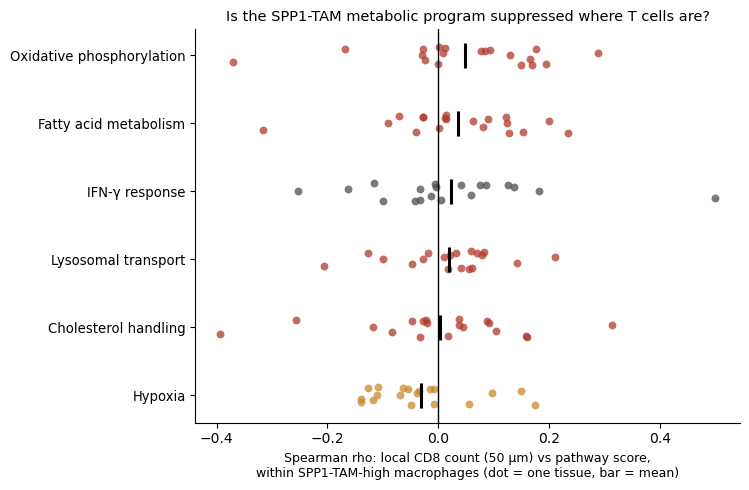

In [23]:
# %% -- §I: does local CD8 density predict the macrophage metabolic state, within tissue? --
from scipy.stats import spearmanr

CD8_LABEL   = "CD8_T"
FOCUS_PATHS = [p for p in ["Cholesterol_Homeo", "OxPhos", "FattyAcid_Metab", "Lysosomal_Transport",
                           "Hypoxia", "IFN_gamma"] if p in path_cols]
assert CD8_LABEL in set(adata.obs[CELL_TYPE_COL].astype(str)), f"{CD8_LABEL} not in {CELL_TYPE_COL}"
print("pathways:", [LABEL_OF[p] for p in FOCUS_PATHS])

rows, cov = [], []
for ti, t in enumerate(TISSUES, 1):
    mask, xy = coords_um_for(adata, sdata, t)
    obs_t = adata.obs.loc[mask]
    mac_u = obs_t["is_mac"].values.astype(bool)
    cd8_u = (obs_t[CELL_TYPE_COL].astype(str).values == CD8_LABEL)
    m = tissue_meta.loc[t]
    if mac_u.sum() < MIN_MACS_FOR_MORAN or cd8_u.sum() < 20:
        print(f"skip {t}: macs={int(mac_u.sum())} CD8={int(cd8_u.sum())}"); continue

    nn = NearestNeighbors(radius=float(NICHE_RADIUS_UM)).fit(xy[cd8_u])
    G = nn.radius_neighbors_graph(xy[mac_u], radius=float(NICHE_RADIUS_UM), mode="connectivity")
    n_cd8 = np.asarray(G.sum(1)).ravel()
    del G

    tam_hi = obs_t.loc[mac_u, "tam_high"].values.astype(bool)
    cov.append({"tissue": t, "rt_status": m["rt_status"], "n_mac": int(mac_u.sum()),
                "n_cd8": int(cd8_u.sum()), "pct_mac_with_cd8": 100 * float((n_cd8 > 0).mean()),
                "median_cd8_local": float(np.median(n_cd8)),
                "pct_tamhigh_with_cd8": 100 * float((n_cd8[tam_hi] > 0).mean()) if tam_hi.sum() else np.nan})

    for subset, tag in [(np.ones_like(tam_hi), "all_macs"), (tam_hi, "tam_high")]:
        if subset.sum() < MIN_MACS_FOR_MORAN or np.std(n_cd8[subset]) == 0:
            continue
        for short in FOCUS_PATHS:
            v = obs_t.loc[mac_u, f"{short}_score"].to_numpy(float)[subset]
            x = n_cd8[subset]
            if np.std(v) == 0:
                continue
            rho, p = spearmanr(x, v)
            rows.append({"tissue": t, "cond": m["cond"], "tumor_loc": m["tumor_loc"],
                         "cart": m["cart"], "rt_status": m["rt_status"], "mac_set": tag,
                         "pathway": short, "label": LABEL_OF[short], "tier": TIER_OF[short],
                         "n": int(subset.sum()), "rho": rho, "p": p})
    print(f"[{ti}/{len(TISSUES)}] {t} macs={int(mac_u.sum()):,} CD8={int(cd8_u.sum()):,} "
          f"({cov[-1]['pct_mac_with_cd8']:.0f}% of macs have a CD8 within {NICHE_RADIUS_UM}um)", flush=True)

cd8_cov = pd.DataFrame(cov); cd8_link = pd.DataFrame(rows)
cd8_cov.to_csv(OUT_DIR / "cd8_local_coverage.csv", index=False)
cd8_link.to_csv(OUT_DIR / "cd8_vs_mac_metabolism_long.csv", index=False)

print("\n=== POWER CHECK: how many macrophages actually have a CD8 neighbour? ===")
print(cd8_cov.groupby("rt_status", observed=True)[
    ["n_mac", "n_cd8", "pct_mac_with_cd8", "pct_tamhigh_with_cd8", "median_cd8_local"]]
    .mean().round(1).to_string())
print("\n  If pct_mac_with_cd8 is small (<20%), most macs contribute a tied zero and every rho")
print("  below is attenuated toward 0 — a null would then be uninformative.")

for tag in ["tam_high", "all_macs"]:
    d = cd8_link[cd8_link["mac_set"] == tag]
    if d.empty:
        continue
    s = (d.groupby(["tier", "label"], observed=True)
         .agg(n_tissues=("tissue", "count"), mean_rho=("rho", "mean"),
              frac_neg=("rho", lambda x: float((x < 0).mean())),
              frac_p05=("p", lambda x: float((x < 0.05).mean())))
         .reset_index().sort_values("mean_rho"))
    print(f"\n=== §I  local CD8 density vs macrophage pathway score  [{tag}] ===")
    print(s.round(3).to_string(index=False))
    print("  mean_rho < 0 with frac_neg >= 0.75 = that program is suppressed near T cells.")
    if tag == "tam_high":
        by_rt = (d.groupby(["rt_status", "tier"], observed=True)["rho"].mean().unstack("tier"))
        print("\n  by RT status (does RT strengthen the T-cell/metabolism antagonism?):")
        print(by_rt.round(3).to_string())

d = cd8_link[cd8_link["mac_set"] == "tam_high"]
if not d.empty:
    order = d.groupby("label", observed=True)["rho"].mean().sort_values().index.tolist()
    fig, ax = plt.subplots(figsize=(7.6, 0.5 * len(order) + 2))
    for i, lab in enumerate(order):
        s = d[d["label"] == lab]
        col = TIER_C.get(s["tier"].iloc[0], "#777")
        ax.scatter(s["rho"], np.full(len(s), i) + np.random.default_rng(SEED).uniform(-.14, .14, len(s)),
                   s=32, color=col, alpha=.75, linewidths=0)
        ax.hlines(i, s["rho"].mean(), s["rho"].mean(), lw=0)
        ax.plot([s["rho"].mean()], [i], "|", color="k", ms=18, mew=2.2, zorder=5)
    ax.axvline(0, color="k", lw=1)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=9.5)
    ax.set_xlabel(f"Spearman rho: local CD8 count ({NICHE_RADIUS_UM} µm) vs pathway score,\n"
                  "within SPP1-TAM-high macrophages (dot = one tissue, bar = mean)", fontsize=9)
    ax.set_title("Is the SPP1-TAM metabolic program suppressed where T cells are?", fontsize=10.5)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
    fig.tight_layout(); fig.savefig(FIG_DIR / "cd8_vs_mac_metabolism.png", dpi=300, bbox_inches="tight")
    plt.show(); plt.close(fig)